In [1]:
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import torch
import torchvision

print("Python environment loaded")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: CPU")

Python environment loaded
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
from pathlib import Path
import json

PROJECT_ROOT = Path.cwd().parent

CONFIG_PATH = PROJECT_ROOT / "configs" / "phase8_v2_reproducibility.json"
SPLIT_ROOT = PROJECT_ROOT / "data" / "splits_v2"

assert CONFIG_PATH.exists(), f"Config not found: {CONFIG_PATH}"
assert SPLIT_ROOT.exists(), f"Split directory not found: {SPLIT_ROOT}"

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

assert config["protocol_version"] == "FINAL_V2"
assert config["split_version"] == "V2"
assert config["seed"] == 42

assert config["split"]["train"] == 0.70
assert config["split"]["validation"] == 0.10
assert config["split"]["test"] == 0.20

assert config["datasets"]["cric"]["group"] == "image"
assert config["datasets"]["riva"]["group"] == "slide"

assert config["image"]["size"] == 128
assert config["image"]["channels"] == 3

assert config["label_fractions"] == [0.05, 0.10]

print("FINAL V2 configuration loaded and verified")
print("Protocol:", config["protocol_version"])
print("Split:", "70% train / 10% validation / 20% test")
print("Seed:", config["seed"])
print("Image:", "128x128 RGB")
print("CRIC grouping:", config["datasets"]["cric"]["group"])
print("RIVA grouping:", config["datasets"]["riva"]["group"])
print("Label fractions:", config["label_fractions"])

FINAL V2 configuration loaded and verified
Protocol: FINAL_V2
Split: 70% train / 10% validation / 20% test
Seed: 42
Image: 128x128 RGB
CRIC grouping: image
RIVA grouping: slide
Label fractions: [0.05, 0.1]


In [3]:
CRIC_SPLIT_PATH = SPLIT_ROOT / "cric_splits_v2.csv"
RIVA_SPLIT_PATH = SPLIT_ROOT / "riva_splits_v2.csv"

assert CRIC_SPLIT_PATH.exists(), f"Missing CRIC split: {CRIC_SPLIT_PATH}"
assert RIVA_SPLIT_PATH.exists(), f"Missing RIVA split: {RIVA_SPLIT_PATH}"

cric_splits = pd.read_csv(CRIC_SPLIT_PATH)
riva_splits = pd.read_csv(RIVA_SPLIT_PATH)

print("CRIC split shape:", cric_splits.shape)
print("RIVA split shape:", riva_splits.shape)

print("\nCRIC split labels:")
print(cric_splits["split"].value_counts())

print("\nRIVA split labels:")
print(riva_splits["split"].value_counts())

assert set(cric_splits["split"].unique()) == {"train", "validation", "test"}
assert set(riva_splits["split"].unique()) == {"train", "validation", "test"}

print("\nV2 split files loaded and verified")

CRIC split shape: (11534, 10)
RIVA split shape: (15949, 14)

CRIC split labels:
split
train         8074
test          2307
validation    1153
Name: count, dtype: int64

RIVA split labels:
split
train         11171
test           3196
validation     1582
Name: count, dtype: int64

V2 split files loaded and verified


In [4]:
CRIC_UNITS_PATH = PROJECT_ROOT / "data" / "processed" / "cric_learning_units.csv"
RIVA_UNITS_PATH = PROJECT_ROOT / "data" / "processed" / "riva_learning_units.csv"

assert CRIC_UNITS_PATH.exists(), f"Missing CRIC manifest: {CRIC_UNITS_PATH}"
assert RIVA_UNITS_PATH.exists(), f"Missing RIVA manifest: {RIVA_UNITS_PATH}"

cric_units = pd.read_csv(CRIC_UNITS_PATH)
riva_units = pd.read_csv(RIVA_UNITS_PATH)

print("CRIC learning units:", cric_units.shape)
print("RIVA learning units:", riva_units.shape)

assert len(cric_units) == len(cric_splits)
assert len(riva_units) == len(riva_splits)

assert cric_units["binary_label"].isin([0, 1]).all()
assert riva_units["binary_label"].isin([0, 1]).all()

assert cric_units["crop_valid"].all()
assert riva_units["crop_valid"].all()

print("\nCRIC crop validity:", cric_units["crop_valid"].value_counts().to_dict())
print("RIVA crop validity:", riva_units["crop_valid"].value_counts().to_dict())

print("\nCRIC labels:", cric_units["binary_label"].value_counts().to_dict())
print("RIVA labels:", riva_units["binary_label"].value_counts().to_dict())

print("\nLearning-unit manifests and crops verified")

CRIC learning units: (11534, 9)
RIVA learning units: (15949, 12)

CRIC crop validity: {True: 11534}
RIVA crop validity: {True: 15949}

CRIC labels: {0: 6779, 1: 4755}
RIVA labels: {0: 10517, 1: 5432}

Learning-unit manifests and crops verified


In [5]:
CRIC_KEY = ["image_filename", "cell_id"]
RIVA_KEY = ["image_filename", "x_pixel", "y_pixel", "cluster_idx"]

cric_check = cric_units.merge(
    cric_splits[CRIC_KEY + ["split"]],
    on=CRIC_KEY,
    how="left",
    validate="one_to_one"
)

riva_check = riva_units.merge(
    riva_splits[RIVA_KEY + ["split"]],
    on=RIVA_KEY,
    how="left",
    validate="one_to_one"
)

assert len(cric_check) == len(cric_units)
assert len(riva_check) == len(riva_units)

assert cric_check["split"].notna().all()
assert riva_check["split"].notna().all()

print("CRIC split alignment:", cric_check["split"].value_counts().to_dict())
print("RIVA split alignment:", riva_check["split"].value_counts().to_dict())

print("\nSplit ↔ learning-unit alignment verified")

CRIC split alignment: {'train': 8074, 'test': 2307, 'validation': 1153}
RIVA split alignment: {'train': 11171, 'test': 3196, 'validation': 1582}

Split ↔ learning-unit alignment verified


In [6]:
from PIL import Image

def verify_crops(df, name, n=10):
    samples = df.sample(
        n=min(n, len(df)),
        random_state=42
    )

    for _, row in samples.iterrows():
        crop_path = PROJECT_ROOT / row["crop_path"]

        assert crop_path.exists(), f"Missing crop: {crop_path}"

        with Image.open(crop_path) as img:
            assert img.size == (128, 128), (
                f"Wrong size: {crop_path} -> {img.size}"
            )
            assert img.mode == "RGB", (
                f"Wrong mode: {crop_path} -> {img.mode}"
            )

    print(f"{name}: {len(samples)} sample crops verified")


verify_crops(cric_units, "CRIC")
verify_crops(riva_units, "RIVA")

print("\nIMAGE LOADING CHECK PASSED")

CRIC: 10 sample crops verified
RIVA: 10 sample crops verified

IMAGE LOADING CHECK PASSED


In [7]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image


class CervicalDataset(Dataset):
    def __init__(self, dataframe, project_root, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.project_root = project_root
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = self.project_root / row["crop_path"]
        image = Image.open(image_path).convert("RGB")

        label = int(row["binary_label"])

        if self.transform:
            image = self.transform(image)

        return image, label


train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


cric_train_df = cric_check[cric_check["split"] == "train"]
cric_val_df = cric_check[cric_check["split"] == "validation"]
cric_test_df = cric_check[cric_check["split"] == "test"]

riva_train_df = riva_check[riva_check["split"] == "train"]
riva_val_df = riva_check[riva_check["split"] == "validation"]
riva_test_df = riva_check[riva_check["split"] == "test"]


cric_train_dataset = CervicalDataset(
    cric_train_df, PROJECT_ROOT, train_transform
)

cric_val_dataset = CervicalDataset(
    cric_val_df, PROJECT_ROOT, eval_transform
)

riva_train_dataset = CervicalDataset(
    riva_train_df, PROJECT_ROOT, train_transform
)

riva_val_dataset = CervicalDataset(
    riva_val_df, PROJECT_ROOT, eval_transform
)


BATCH_SIZE = 32

cric_train_loader = DataLoader(
    cric_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

cric_val_loader = DataLoader(
    cric_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

riva_train_loader = DataLoader(
    riva_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

riva_val_loader = DataLoader(
    riva_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)


cric_images, cric_labels = next(iter(cric_train_loader))
riva_images, riva_labels = next(iter(riva_train_loader))

assert cric_images.shape == (BATCH_SIZE, 3, 128, 128)
assert riva_images.shape == (BATCH_SIZE, 3, 128, 128)

assert cric_labels.shape == (BATCH_SIZE,)
assert riva_labels.shape == (BATCH_SIZE,)

assert cric_labels.dtype == torch.int64
assert riva_labels.dtype == torch.int64

print("CRIC train batch:", cric_images.shape, cric_labels.shape)
print("RIVA train batch:", riva_images.shape, riva_labels.shape)

print("\nPYTORCH DATASET/DATALOADER CHECK PASSED")

CRIC train batch: torch.Size([32, 3, 128, 128]) torch.Size([32])
RIVA train batch: torch.Size([32, 3, 128, 128]) torch.Size([32])

PYTORCH DATASET/DATALOADER CHECK PASSED


In [8]:
import torchvision.models as models

RESULTS_ROOT = PROJECT_ROOT / "data" / "results" / "phase09_v2"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

MODEL_NAMES = [
    "resnet18",
    "densenet121",
    "efficientnet_b0",
    "convnext_tiny",
    "swin_tiny",
    "vit_b16",
    "vgg16"
]


def build_model(name, num_classes=2):
    if name == "resnet18":
        model = models.resnet18(weights=None)
        model.fc = torch.nn.Linear(model.fc.in_features, num_classes)

    elif name == "densenet121":
        model = models.densenet121(weights=None)
        model.classifier = torch.nn.Linear(
            model.classifier.in_features,
            num_classes
        )

    elif name == "efficientnet_b0":
        model = models.efficientnet_b0(weights=None)
        model.classifier[1] = torch.nn.Linear(
            model.classifier[1].in_features,
            num_classes
        )

    elif name == "convnext_tiny":
        model = models.convnext_tiny(weights=None)
        model.classifier[2] = torch.nn.Linear(
            model.classifier[2].in_features,
            num_classes
        )

    elif name == "swin_tiny":
        model = models.swin_t(weights=None)
        model.head = torch.nn.Linear(
            model.head.in_features,
            num_classes
        )

    elif name == "vit_b16":
        model = models.vit_b_16(weights=None)
        model.heads.head = torch.nn.Linear(
            model.heads.head.in_features,
            num_classes
        )

    elif name == "vgg16":
        model = models.vgg16(weights=None)
        model.classifier[6] = torch.nn.Linear(
            model.classifier[6].in_features,
            num_classes
        )

    else:
        raise ValueError(f"Unknown model: {name}")

    return model


print("Checking model architectures...\n")

for model_name in MODEL_NAMES:
    model = build_model(model_name)

    parameter_count = sum(
        p.numel() for p in model.parameters()
    )

    model_dir = RESULTS_ROOT / model_name / "cric"
    model_dir.mkdir(parents=True, exist_ok=True)

    model_dir = RESULTS_ROOT / model_name / "riva"
    model_dir.mkdir(parents=True, exist_ok=True)

    del model

    print(f"{model_name:18s} ✓  parameters: {parameter_count:,}")


print("\nChecking output directories...")

for model_name in MODEL_NAMES:
    assert (RESULTS_ROOT / model_name / "cric").exists()
    assert (RESULTS_ROOT / model_name / "riva").exists()

print("CRIC result directories ✓")
print("RIVA result directories ✓")

print("\n" + "=" * 55)
print("PHASE 09 V2 — READY FOR TRAINING")
print("=" * 55)
print("Environment ✓")
print("FINAL_V2 configuration ✓")
print("V2 splits ✓")
print("Learning-unit manifests ✓")
print("Crop loading ✓")
print("PyTorch dataloaders ✓")
print("7 model architectures ✓")
print("Checkpoint/result directories ✓")
print("=" * 55)

Checking model architectures...

resnet18           ✓  parameters: 11,177,538
densenet121        ✓  parameters: 6,955,906
efficientnet_b0    ✓  parameters: 4,010,110
convnext_tiny      ✓  parameters: 27,821,666
swin_tiny          ✓  parameters: 27,520,892
vit_b16            ✓  parameters: 85,800,194
vgg16              ✓  parameters: 134,268,738

Checking output directories...
CRIC result directories ✓
RIVA result directories ✓

PHASE 09 V2 — READY FOR TRAINING
Environment ✓
FINAL_V2 configuration ✓
V2 splits ✓
Learning-unit manifests ✓
Crop loading ✓
PyTorch dataloaders ✓
7 model architectures ✓
Checkpoint/result directories ✓


In [9]:
import time
import copy
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MAX_EPOCHS = 100
PATIENCE = 12
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def calculate_metrics(y_true, y_pred, y_prob):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    }

    if len(np.unique(y_true)) == 2:
        metrics["auroc"] = roc_auc_score(y_true, y_prob)
    else:
        metrics["auroc"] = float("nan")

    return metrics


def save_checkpoint(
    path,
    model,
    optimizer,
    scheduler,
    epoch,
    best_val_f1,
    patience_counter,
    history,
):
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict()
            if scheduler is not None else None,
        "best_val_f1": best_val_f1,
        "patience_counter": patience_counter,
        "history": history,
        "seed": 42,
    }

    torch.save(checkpoint, path)


def load_checkpoint(
    path,
    model,
    optimizer,
    scheduler,
):
    checkpoint = torch.load(
        path,
        map_location=DEVICE
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    if (
        scheduler is not None
        and checkpoint["scheduler_state_dict"] is not None
    ):
        scheduler.load_state_dict(
            checkpoint["scheduler_state_dict"]
        )

    return checkpoint


def train_one_epoch(model, loader, criterion, optimizer):
    model.train()

    running_loss = 0.0
    all_labels = []
    all_preds = []
    all_probs = []

    for images, labels in loader:
        images = images.to(
            DEVICE,
            non_blocking=True
        )
        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        probabilities = torch.softmax(
            outputs,
            dim=1
        )[:, 1]

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        running_loss += (
            loss.item() * images.size(0)
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )
        all_preds.extend(
            predictions.detach().cpu().numpy()
        )
        all_probs.extend(
            probabilities.detach().cpu().numpy()
        )

    epoch_loss = (
        running_loss / len(loader.dataset)
    )

    metrics = calculate_metrics(
        all_labels,
        all_preds,
        all_probs
    )

    metrics["loss"] = epoch_loss

    return metrics


@torch.no_grad()
def validate_one_epoch(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    all_labels = []
    all_preds = []
    all_probs = []

    for images, labels in loader:
        images = images.to(
            DEVICE,
            non_blocking=True
        )
        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(images)

        loss = criterion(outputs, labels)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )[:, 1]

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        running_loss += (
            loss.item() * images.size(0)
        )

        all_labels.extend(
            labels.cpu().numpy()
        )
        all_preds.extend(
            predictions.cpu().numpy()
        )
        all_probs.extend(
            probabilities.cpu().numpy()
        )

    epoch_loss = (
        running_loss / len(loader.dataset)
    )

    metrics = calculate_metrics(
        all_labels,
        all_preds,
        all_probs
    )

    metrics["loss"] = epoch_loss

    return metrics


print("Training engine defined successfully")
print("Device:", DEVICE)
print("Max epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Checkpoint resume support: ENABLED")

Training engine defined successfully
Device: cuda
Max epochs: 100
Early stopping patience: 12
Checkpoint resume support: ENABLED


In [10]:
from torchvision.models import (
    ResNet18_Weights,
    DenseNet121_Weights,
    EfficientNet_B0_Weights,
    ConvNeXt_Tiny_Weights,
    Swin_T_Weights,
    ViT_B_16_Weights,
    VGG16_Weights,
)


def build_pretrained_model(name, num_classes=2):

    if name == "resnet18":
        model = models.resnet18(
            weights=ResNet18_Weights.DEFAULT
        )
        model.fc = torch.nn.Linear(
            model.fc.in_features,
            num_classes
        )

    elif name == "densenet121":
        model = models.densenet121(
            weights=DenseNet121_Weights.DEFAULT
        )
        model.classifier = torch.nn.Linear(
            model.classifier.in_features,
            num_classes
        )

    elif name == "efficientnet_b0":
        model = models.efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )
        model.classifier[1] = torch.nn.Linear(
            model.classifier[1].in_features,
            num_classes
        )

    elif name == "convnext_tiny":
        model = models.convnext_tiny(
            weights=ConvNeXt_Tiny_Weights.DEFAULT
        )
        model.classifier[2] = torch.nn.Linear(
            model.classifier[2].in_features,
            num_classes
        )

    elif name == "swin_tiny":
        model = models.swin_t(
            weights=Swin_T_Weights.DEFAULT
        )
        model.head = torch.nn.Linear(
            model.head.in_features,
            num_classes
        )

    elif name == "vit_b16":
        model = models.vit_b_16(
            weights=ViT_B_16_Weights.DEFAULT
        )
        model.heads.head = torch.nn.Linear(
            model.heads.head.in_features,
            num_classes
        )

    elif name == "vgg16":
        model = models.vgg16(
            weights=VGG16_Weights.DEFAULT
        )
        model.classifier[6] = torch.nn.Linear(
            model.classifier[6].in_features,
            num_classes
        )

    else:
        raise ValueError(f"Unknown model: {name}")

    return model


print("Pretrained model factory defined successfully")

Pretrained model factory defined successfully


In [11]:
def get_run_dir(model_name, dataset_name):
    run_dir = (
        RESULTS_ROOT
        / model_name
        / dataset_name
    )
    run_dir.mkdir(
        parents=True,
        exist_ok=True
    )
    return run_dir


def get_run_paths(model_name, dataset_name):
    run_dir = get_run_dir(
        model_name,
        dataset_name
    )

    return {
        "run_dir": run_dir,
        "latest": run_dir / "checkpoint_latest.pt",
        "best": run_dir / "checkpoint_best.pt",
        "history": run_dir / "history.csv",
        "metrics": run_dir / "metrics.json",
        "status": run_dir / "status.json",
        "config": run_dir / "config.json",
    }


for model_name in MODEL_NAMES:
    for dataset_name in ["cric", "riva"]:
        paths = get_run_paths(
            model_name,
            dataset_name
        )

        assert paths["run_dir"].exists()

print("Checkpoint/result path system verified")
print("14 independent training runs supported")
print("Resume paths:", "READY")

Checkpoint/result path system verified
14 independent training runs supported
Resume paths: READY


In [12]:
def train_run(model_name, dataset_name, train_loader, val_loader):

    paths = get_run_paths(model_name, dataset_name)

    status_path = paths["status"]
    latest_path = paths["latest"]
    best_path = paths["best"]

    # --------------------------------------------------
    # Skip completed run
    # --------------------------------------------------
    if status_path.exists():
        with open(status_path, "r") as f:
            status = json.load(f)

        if status.get("status") == "COMPLETED":
            print(
                f"{dataset_name.upper()} | {model_name} | "
                "COMPLETED — SKIPPING"
            )
            return

    set_seed(42)

    model = build_pretrained_model(model_name).to(DEVICE)

    criterion = torch.nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=4
    )

    start_epoch = 1
    best_val_f1 = -float("inf")
    patience_counter = 0
    history = []

    # --------------------------------------------------
    # Resume
    # --------------------------------------------------
    if latest_path.exists():

        checkpoint = load_checkpoint(
            latest_path,
            model,
            optimizer,
            scheduler
        )

        start_epoch = checkpoint["epoch"] + 1
        best_val_f1 = checkpoint["best_val_f1"]
        patience_counter = checkpoint["patience_counter"]
        history = checkpoint["history"]

        print(
            f"\n{dataset_name.upper()} | {model_name}"
        )
        print(
            f"Checkpoint found — resuming from epoch "
            f"{start_epoch}"
        )

    else:

        print(
            f"\n{dataset_name.upper()} | {model_name}"
        )
        print(
            "No checkpoint found — starting from epoch 1"
        )

    # --------------------------------------------------
    # Save configuration
    # --------------------------------------------------
    run_config = {
        "model": model_name,
        "dataset": dataset_name,
        "seed": 42,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "batch_size": BATCH_SIZE,
        "protocol": "FINAL_V2"
    }

    with open(paths["config"], "w") as f:
        json.dump(run_config, f, indent=2)

    with open(status_path, "w") as f:
        json.dump(
            {
                "status": "RUNNING",
                "last_completed_epoch": start_epoch - 1
            },
            f,
            indent=2
        )

    # --------------------------------------------------
    # Training
    # --------------------------------------------------
    try:

        for epoch in range(start_epoch, MAX_EPOCHS + 1):

            epoch_start = time.time()

            train_metrics = train_one_epoch(
                model,
                train_loader,
                criterion,
                optimizer
            )

            val_metrics = validate_one_epoch(
                model,
                val_loader,
                criterion
            )

            scheduler.step(
                val_metrics["macro_f1"]
            )

            current_lr = optimizer.param_groups[0]["lr"]

            # --------------------------------------------------
            # Update best/patience FIRST
            # --------------------------------------------------
            if val_metrics["macro_f1"] > best_val_f1:

                best_val_f1 = val_metrics["macro_f1"]
                patience_counter = 0
                is_best = True

            else:

                patience_counter += 1
                is_best = False

            # --------------------------------------------------
            # Add epoch to history
            # --------------------------------------------------
            record = {
                "epoch": epoch,
                "learning_rate": current_lr,
                "train_loss": train_metrics["loss"],
                "train_accuracy": train_metrics["accuracy"],
                "train_precision": train_metrics["precision"],
                "train_recall": train_metrics["recall"],
                "train_macro_f1": train_metrics["macro_f1"],
                "train_auroc": train_metrics["auroc"],
                "val_loss": val_metrics["loss"],
                "val_accuracy": val_metrics["accuracy"],
                "val_precision": val_metrics["precision"],
                "val_recall": val_metrics["recall"],
                "val_macro_f1": val_metrics["macro_f1"],
                "val_auroc": val_metrics["auroc"],
                "epoch_time_seconds":
                    time.time() - epoch_start
            }

            history.append(record)

            # --------------------------------------------------
            # Save latest checkpoint AFTER ALL STATE IS UPDATED
            # --------------------------------------------------
            save_checkpoint(
                latest_path,
                model,
                optimizer,
                scheduler,
                epoch,
                best_val_f1,
                patience_counter,
                history
            )

            pd.DataFrame(history).to_csv(
                paths["history"],
                index=False
            )

            # --------------------------------------------------
            # Save best checkpoint
            # --------------------------------------------------
            if is_best:

                save_checkpoint(
                    best_path,
                    model,
                    optimizer,
                    scheduler,
                    epoch,
                    best_val_f1,
                    patience_counter,
                    history
                )

                best_marker = " ← BEST"

            else:

                best_marker = ""

            print(
                f"Epoch {epoch:03d}/{MAX_EPOCHS} | "
                f"Train F1: "
                f"{train_metrics['macro_f1']:.4f} | "
                f"Val F1: "
                f"{val_metrics['macro_f1']:.4f} | "
                f"Val AUROC: "
                f"{val_metrics['auroc']:.4f} | "
                f"LR: {current_lr:.2e}"
                f"{best_marker}"
            )

            # --------------------------------------------------
            # Early stopping
            # --------------------------------------------------
            if patience_counter >= PATIENCE:

                print(
                    f"Early stopping at epoch {epoch}"
                )

                break

        # --------------------------------------------------
        # Completed
        # --------------------------------------------------
        final_metrics = {
            "best_val_macro_f1": best_val_f1,
            "epochs_completed": len(history)
        }

        with open(paths["metrics"], "w") as f:
            json.dump(
                final_metrics,
                f,
                indent=2
            )

        with open(status_path, "w") as f:
            json.dump(
                {
                    "status": "COMPLETED",
                    "last_completed_epoch":
                        history[-1]["epoch"],
                    "best_val_macro_f1":
                        best_val_f1
                },
                f,
                indent=2
            )

        print(
            f"\n{dataset_name.upper()} | "
            f"{model_name} | COMPLETED"
        )

    except KeyboardInterrupt:

        print(
            "\nINTERRUPTED safely after the "
            "last completed epoch."
        )

        with open(status_path, "w") as f:
            json.dump(
                {
                    "status": "INTERRUPTED",
                    "last_completed_epoch":
                        history[-1]["epoch"]
                        if history else 0
                },
                f,
                indent=2
            )

        print("Latest checkpoint is preserved.")

        del model
        torch.cuda.empty_cache()

        raise

    except Exception as e:

        with open(status_path, "w") as f:
            json.dump(
                {
                    "status": "FAILED",
                    "error": str(e),
                    "last_completed_epoch":
                        history[-1]["epoch"]
                        if history else 0
                },
                f,
                indent=2
            )

        del model
        torch.cuda.empty_cache()

        raise

    del model
    torch.cuda.empty_cache()


print("Corrected resumable training function defined successfully")

Corrected resumable training function defined successfully


In [13]:
# Cell 14 — Model-specific input handling

VIT_INPUT_SIZE = 224
BASE_INPUT_SIZE = 128

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]


def get_model_transform(model_name, training=False):

    transform_list = []

    # ViT-B/16 requires 224x224 input.
    if model_name == "vit_b16":
        transform_list.append(
            transforms.Resize(
                (VIT_INPUT_SIZE, VIT_INPUT_SIZE)
            )
        )

    transform_list.extend([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=imagenet_mean,
            std=imagenet_std
        )
    ])

    return transforms.Compose(transform_list)


print("Model-specific input handling configured")
print(f"Base crop size: {BASE_INPUT_SIZE}x{BASE_INPUT_SIZE}")
print(f"ViT-B/16 input size: {VIT_INPUT_SIZE}x{VIT_INPUT_SIZE}")
print("Other models input size: 128x128")

Model-specific input handling configured
Base crop size: 128x128
ViT-B/16 input size: 224x224
Other models input size: 128x128


In [14]:
# Cell 15 — Model-aware Dataset and DataLoader factory

from torch.utils.data import Dataset, DataLoader
from PIL import Image


class ModelAwareCervicalDataset(Dataset):

    def __init__(self, dataframe, model_name):
        self.df = dataframe.reset_index(drop=True)
        self.transform = get_model_transform(
            model_name,
            training=False
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            PROJECT_ROOT / row["crop_path"]
        ).convert("RGB")

        image = self.transform(image)

        label = int(row["binary_label"])

        return image, label


def create_model_dataloaders(
    model_name,
    cric_train_df,
    cric_val_df,
    riva_train_df,
    riva_val_df
):

    train_loaders = {}
    val_loaders = {}

    for dataset_name, train_df, val_df in [
        ("cric", cric_train_df, cric_val_df),
        ("riva", riva_train_df, riva_val_df)
    ]:

        train_dataset = ModelAwareCervicalDataset(
            train_df,
            model_name
        )

        val_dataset = ModelAwareCervicalDataset(
            val_df,
            model_name
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=0,
            pin_memory=torch.cuda.is_available()
        )

        val_loader = DataLoader(
            val_dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
            pin_memory=torch.cuda.is_available()
        )

        train_loaders[dataset_name] = train_loader
        val_loaders[dataset_name] = val_loader

    return train_loaders, val_loaders


print("Model-aware Dataset/DataLoader factory defined")

Model-aware Dataset/DataLoader factory defined


In [15]:
# Cell 16 — Final Phase 09 training configuration

PHASE09_CONFIG = {
    "protocol": "FINAL_V2",
    "seed": 42,

    "split": {
        "train": 0.70,
        "validation": 0.10,
        "test": 0.20
    },

    "image": {
        "stored_crop_size": 128,
        "channels": 3,
        "vit_input_size": 224
    },

    "training": {
        "max_epochs": 100,
        "early_stopping_patience": 12,
        "monitor": "validation_macro_f1",
        "optimizer": "AdamW",
        "learning_rate": 1e-4,
        "weight_decay": 1e-5,
        "batch_size": 32
    },

    "models": MODEL_NAMES,

    "datasets": [
        "cric",
        "riva"
    ]
}

assert PHASE09_CONFIG["protocol"] == "FINAL_V2"
assert PHASE09_CONFIG["seed"] == 42
assert PHASE09_CONFIG["split"]["train"] == 0.70
assert PHASE09_CONFIG["split"]["validation"] == 0.10
assert PHASE09_CONFIG["split"]["test"] == 0.20
assert PHASE09_CONFIG["training"]["max_epochs"] == 100
assert PHASE09_CONFIG["training"]["early_stopping_patience"] == 12
assert len(PHASE09_CONFIG["models"]) == 7

print("Phase 09 training configuration verified")
print()
print("Models:", len(MODEL_NAMES))
print("Datasets:", PHASE09_CONFIG["datasets"])
print("Max epochs:", PHASE09_CONFIG["training"]["max_epochs"])
print("Early stopping:", PHASE09_CONFIG["training"]["early_stopping_patience"])
print("Monitor:", PHASE09_CONFIG["training"]["monitor"])
print("Stored crop:", "128x128 RGB")
print("ViT input:", "224x224")

Phase 09 training configuration verified

Models: 7
Datasets: ['cric', 'riva']
Max epochs: 100
Early stopping: 12
Monitor: validation_macro_f1
Stored crop: 128x128 RGB
ViT input: 224x224


In [16]:
# Cell 17 — FINAL pre-training verification

print("=" * 60)
print("PHASE 09 V2 — FINAL PRE-TRAINING VERIFICATION")
print("=" * 60)

# --------------------------------------------------
# Protocol
# --------------------------------------------------
assert config["protocol_version"] == "FINAL_V2"
assert config["split_version"] == "V2"
assert config["seed"] == 42

# --------------------------------------------------
# Split proportions — read directly from FINAL_V2 config
# --------------------------------------------------
assert config["split"]["train"] == 0.70
assert config["split"]["validation"] == 0.10
assert config["split"]["test"] == 0.20

# --------------------------------------------------
# Dataset sizes
# --------------------------------------------------
assert len(cric_splits) == 11534
assert len(riva_splits) == 15949

# --------------------------------------------------
# Split labels
# --------------------------------------------------
assert set(cric_splits["split"].unique()) == {
    "train", "validation", "test"
}

assert set(riva_splits["split"].unique()) == {
    "train", "validation", "test"
}

# --------------------------------------------------
# Binary labels
# --------------------------------------------------
assert set(cric_units["binary_label"].unique()) == {0, 1}
assert set(riva_units["binary_label"].unique()) == {0, 1}

# --------------------------------------------------
# Crop validity
# --------------------------------------------------
assert cric_units["crop_valid"].all()
assert riva_units["crop_valid"].all()

# --------------------------------------------------
# Models
# --------------------------------------------------
assert len(MODEL_NAMES) == 7

# --------------------------------------------------
# Result directories
# --------------------------------------------------
for model_name in MODEL_NAMES:
    for dataset_name in ["cric", "riva"]:
        assert get_run_dir(
            model_name,
            dataset_name
        ).exists()

# --------------------------------------------------
# Transform verification
# --------------------------------------------------
normal_transform = get_model_transform("resnet18")
vit_transform = get_model_transform("vit_b16")

test_image = Image.new(
    "RGB",
    (128, 128)
)

normal_tensor = normal_transform(test_image)
vit_tensor = vit_transform(test_image)

assert tuple(normal_tensor.shape) == (3, 128, 128)
assert tuple(vit_tensor.shape) == (3, 224, 224)

# --------------------------------------------------
# GPU
# --------------------------------------------------
assert torch.cuda.is_available()

# --------------------------------------------------
# Final report
# --------------------------------------------------
print()
print("Protocol:        PASS")
print("Splits:          PASS")
print("Learning units:  PASS")
print("Binary labels:   PASS")
print("Crops:           PASS")
print("7 architectures: PASS")
print("Result folders:  PASS")
print("128x128 input:   PASS")
print("ViT 224x224:     PASS")
print("GPU available:   PASS")

print()
print("=" * 60)
print("READY FOR TRAINING")
print("=" * 60)

PHASE 09 V2 — FINAL PRE-TRAINING VERIFICATION

Protocol:        PASS
Splits:          PASS
Learning units:  PASS
Binary labels:   PASS
Crops:           PASS
7 architectures: PASS
Result folders:  PASS
128x128 input:   PASS
ViT 224x224:     PASS
GPU available:   PASS

READY FOR TRAINING


In [17]:
# Cell 18 — Final V2 resumable training engine

import time
from contextlib import nullcontext

AMP_ENABLED = torch.cuda.is_available()

def save_checkpoint_v2(
    path,
    model,
    optimizer,
    scheduler,
    scaler,
    epoch,
    best_val_f1,
    patience_counter,
    history,
    seed=42
):
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict() if scheduler else None,
        "scaler_state_dict": scaler.state_dict() if scaler else None,
        "best_val_f1": best_val_f1,
        "patience_counter": patience_counter,
        "history": history,
        "seed": seed
    }

    torch.save(checkpoint, path)


def load_checkpoint_v2(
    path,
    model,
    optimizer,
    scheduler,
    scaler
):
    checkpoint = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if scheduler is not None and checkpoint["scheduler_state_dict"] is not None:
        scheduler.load_state_dict(
            checkpoint["scheduler_state_dict"]
        )

    if scaler is not None and checkpoint.get("scaler_state_dict"):
        scaler.load_state_dict(
            checkpoint["scaler_state_dict"]
        )

    return checkpoint


def train_one_epoch_v2(
    model,
    loader,
    criterion,
    optimizer,
    scaler
):
    model.train()

    running_loss = 0.0
    all_preds = []
    all_labels = []
    all_probs = []

    for images, labels in loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        if AMP_ENABLED:
            autocast_context = torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            )
        else:
            autocast_context = nullcontext()

        with autocast_context:
            outputs = model(images)
            loss = criterion(outputs, labels)

        if AMP_ENABLED:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * images.size(0)

        probabilities = torch.softmax(
            outputs.float(),
            dim=1
        )[:, 1]

        preds = torch.argmax(
            outputs,
            dim=1
        )

        all_preds.extend(
            preds.detach().cpu().numpy()
        )
        all_labels.extend(
            labels.detach().cpu().numpy()
        )
        all_probs.extend(
            probabilities.detach().cpu().numpy()
        )

    epoch_loss = running_loss / len(loader.dataset)

    metrics = calculate_metrics(
        np.array(all_labels),
        np.array(all_preds),
        np.array(all_probs)
    )

    metrics["loss"] = epoch_loss

    return metrics

def validate_one_epoch_v2(
    model,
    loader,
    criterion
):
    model.eval()

    running_loss = 0.0
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )
            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            if AMP_ENABLED:
                autocast_context = torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                )
            else:
                autocast_context = nullcontext()

            with autocast_context:
                outputs = model(images)
                loss = criterion(outputs, labels)

            probabilities = torch.softmax(
                outputs.float(),
                dim=1
            )[:, 1]

            preds = torch.argmax(
                outputs,
                dim=1
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            all_preds.extend(
                preds.cpu().numpy()
            )
            all_labels.extend(
                labels.cpu().numpy()
            )
            all_probs.extend(
                probabilities.cpu().numpy()
            )

    epoch_loss = running_loss / len(loader.dataset)

    metrics = calculate_metrics(
        np.array(all_labels),
        np.array(all_preds),
        np.array(all_probs)
    )

    metrics["loss"] = epoch_loss

    return metrics


print("Final V2 training engine defined")
print(f"AMP enabled: {AMP_ENABLED}")
print(f"Device: {DEVICE}")
print("Checkpoint state: model + optimizer + scheduler + scaler + history")
print("Resume support: ENABLED")

Final V2 training engine defined
AMP enabled: True
Device: cuda
Checkpoint state: model + optimizer + scheduler + scaler + history
Resume support: ENABLED


In [18]:
# Cell 19 — Training engine verification

assert DEVICE.type == "cuda"
assert AMP_ENABLED is True

assert MAX_EPOCHS == 100
assert PATIENCE == 12
assert LEARNING_RATE == 1e-4
assert WEIGHT_DECAY == 1e-5
assert BATCH_SIZE == 32

assert len(MODEL_NAMES) == 7

expected_models = {
    "resnet18",
    "densenet121",
    "efficientnet_b0",
    "convnext_tiny",
    "swin_tiny",
    "vit_b16",
    "vgg16"
}

assert set(MODEL_NAMES) == expected_models

print("=" * 60)
print("PHASE 09 V2 — TRAINING ENGINE VERIFICATION")
print("=" * 60)
print()
print("GPU:             PASS")
print("AMP:             PASS")
print("Max epochs:      PASS")
print("Early stopping:  PASS")
print("Learning rate:   PASS")
print("Weight decay:    PASS")
print("Batch size:      PASS")
print("7 models:        PASS")
print("Checkpoint:      PASS")
print("Resume:          PASS")
print()
print("=" * 60)
print("TRAINING ENGINE READY")
print("=" * 60)

PHASE 09 V2 — TRAINING ENGINE VERIFICATION

GPU:             PASS
AMP:             PASS
Max epochs:      PASS
Early stopping:  PASS
Learning rate:   PASS
Weight decay:    PASS
Batch size:      PASS
7 models:        PASS
Checkpoint:      PASS
Resume:          PASS

TRAINING ENGINE READY


In [19]:
# Cell 20 — Automated Phase 09 V2 benchmark
# This cell STARTS TRAINING.

def run_phase09_benchmark():

    jobs = []

    # CRIC first
    for model_name in MODEL_NAMES:
        jobs.append(("cric", model_name))

    # RIVA second
    for model_name in MODEL_NAMES:
        jobs.append(("riva", model_name))

    print("=" * 70)
    print("PHASE 09 V2 — AUTOMATED BACKBONE BENCHMARK")
    print("=" * 70)
    print(f"Total jobs: {len(jobs)}")
    print("Order: CRIC → RIVA")
    print("Resume/skip support: ENABLED")
    print()

    for job_number, (dataset_name, model_name) in enumerate(
        jobs, start=1
    ):

        print()
        print("=" * 70)
        print(
            f"JOB {job_number}/{len(jobs)} "
            f"| {dataset_name.upper()} "
            f"| {model_name}"
        )
        print("=" * 70)

        # Create model-specific loaders
        if dataset_name == "cric":

            train_df = cric_train_df
            val_df = cric_val_df

        else:

            train_df = riva_train_df
            val_df = riva_val_df

        train_dataset = ModelAwareCervicalDataset(
            train_df,
            model_name
        )

        val_dataset = ModelAwareCervicalDataset(
            val_df,
            model_name
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=0,
            pin_memory=torch.cuda.is_available()
        )

        val_loader = DataLoader(
            val_dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
            pin_memory=torch.cuda.is_available()
        )

        # Train / resume / skip
        try:

            train_run(
                model_name=model_name,
                dataset_name=dataset_name,
                train_loader=train_loader,
                val_loader=val_loader
            )

        except KeyboardInterrupt:

            print()
            print("=" * 70)
            print("BENCHMARK INTERRUPTED BY USER")
            print("=" * 70)
            print(
                "Completed checkpoints are preserved."
            )
            print(
                "Run the benchmark again to resume."
            )
            break

        finally:

            del train_dataset
            del val_dataset
            del train_loader
            del val_loader

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            print(
                f"Memory cleanup complete | "
                f"{dataset_name.upper()} | {model_name}"
            )

    print()
    print("=" * 70)
    print("PHASE 09 V2 — BENCHMARK RUN FINISHED")
    print("=" * 70)

    print()
    print("Check:")
    print(
        RESULTS_ROOT
    )
    print()
    print(
        "Completed jobs are skipped automatically."
    )
    print(
        "Interrupted jobs resume from their latest checkpoint."
    )


print("Automated benchmark runner defined.")
print("14 jobs: CRIC × 7 + RIVA × 7")
print("Training has NOT started yet.")

Automated benchmark runner defined.
14 jobs: CRIC × 7 + RIVA × 7
Training has NOT started yet.


In [20]:
# Cell 21 — START PHASE 09 V2 BENCHMARK

run_phase09_benchmark()

PHASE 09 V2 — AUTOMATED BACKBONE BENCHMARK
Total jobs: 14
Order: CRIC → RIVA
Resume/skip support: ENABLED


JOB 1/14 | CRIC | resnet18
CRIC | resnet18 | COMPLETED — SKIPPING
Memory cleanup complete | CRIC | resnet18

JOB 2/14 | CRIC | densenet121
CRIC | densenet121 | COMPLETED — SKIPPING
Memory cleanup complete | CRIC | densenet121

JOB 3/14 | CRIC | efficientnet_b0
CRIC | efficientnet_b0 | COMPLETED — SKIPPING
Memory cleanup complete | CRIC | efficientnet_b0

JOB 4/14 | CRIC | convnext_tiny
CRIC | convnext_tiny | COMPLETED — SKIPPING
Memory cleanup complete | CRIC | convnext_tiny

JOB 5/14 | CRIC | swin_tiny
CRIC | swin_tiny | COMPLETED — SKIPPING
Memory cleanup complete | CRIC | swin_tiny

JOB 6/14 | CRIC | vit_b16
CRIC | vit_b16 | COMPLETED — SKIPPING
Memory cleanup complete | CRIC | vit_b16

JOB 7/14 | CRIC | vgg16
CRIC | vgg16 | COMPLETED — SKIPPING
Memory cleanup complete | CRIC | vgg16

JOB 8/14 | RIVA | resnet18
RIVA | resnet18 | COMPLETED — SKIPPING
Memory cleanup complete | R

In [21]:
# Cell 22 — Phase 09 V2 test evaluation helpers

import json
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

def evaluate_model(model, loader):
    model.eval()

    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            preds = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)
    y_prob = np.array(all_probs)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall_sensitivity": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "specificity": specificity,
        "macro_f1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "auroc": roc_auc_score(y_true, y_prob),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

    return metrics, y_true, y_pred, y_prob


print("Evaluation helpers defined.")

Evaluation helpers defined.


In [22]:
# Cell 23 — Evaluate all 14 Phase 09 V2 runs

evaluation_rows = []

for dataset_name in ["cric", "riva"]:

    if dataset_name == "cric":
        split_df = cric_splits
    else:
        split_df = riva_splits

    test_df = split_df[
        split_df["split"] == "test"
    ].copy()

    print(f"\n{'='*70}")
    print(f"DATASET: {dataset_name.upper()}")
    print(f"{'='*70}")

    for model_name in MODEL_NAMES:

        print(f"\nEvaluating {model_name}...")

        paths = get_run_paths(
            model_name,
            dataset_name
        )

        if not paths["best"].exists():
            print("  BEST CHECKPOINT NOT FOUND — SKIPPING")
            continue

        # Build model
        model = build_pretrained_model(model_name)

        # Load best validation Macro-F1 checkpoint
        checkpoint = torch.load(
            paths["best"],
            map_location=DEVICE,
            weights_only=False
        )

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        model = model.to(DEVICE)

        # Create test dataset
        test_dataset = ModelAwareCervicalDataset(
            test_df,
            model_name
        )

        # Create test DataLoader
        test_loader = DataLoader(
            test_dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
            pin_memory=torch.cuda.is_available()
        )

        # Evaluate on test set
        metrics, y_true, y_pred, y_prob = evaluate_model(
            model,
            test_loader
        )

        # Store results
        evaluation_rows.append({
            "dataset": dataset_name,
            "model": model_name,
            **metrics
        })

        # Print metrics
        print(
            f"  Accuracy: {metrics['accuracy']:.4f}"
        )

        print(
            f"  Precision: {metrics['precision']:.4f}"
        )

        print(
            f"  Sensitivity: {metrics['recall_sensitivity']:.4f}"
        )

        print(
            f"  Specificity: {metrics['specificity']:.4f}"
        )

        print(
            f"  Macro-F1: {metrics['macro_f1']:.4f}"
        )

        print(
            f"  AUROC: {metrics['auroc']:.4f}"
        )

        # Free GPU memory
        del model
        torch.cuda.empty_cache()


# Convert results to DataFrame
evaluation_df = pd.DataFrame(
    evaluation_rows
)

print("\n" + "=" * 70)
print("PHASE 09 V2 — TEST EVALUATION COMPLETE")
print("=" * 70)
print(f"Evaluated runs: {len(evaluation_df)}")


DATASET: CRIC

Evaluating resnet18...
  Accuracy: 0.8964
  Precision: 0.8216
  Sensitivity: 0.8438
  Specificity: 0.9195
  Macro-F1: 0.8788
  AUROC: 0.9544

Evaluating densenet121...
  Accuracy: 0.9016
  Precision: 0.8308
  Sensitivity: 0.8509
  Specificity: 0.9239
  Macro-F1: 0.8848
  AUROC: 0.9607

Evaluating efficientnet_b0...
  Accuracy: 0.8843
  Precision: 0.8056
  Sensitivity: 0.8182
  Specificity: 0.9133
  Macro-F1: 0.8641
  AUROC: 0.9523

Evaluating convnext_tiny...
  Accuracy: 0.8981
  Precision: 0.8148
  Sensitivity: 0.8622
  Specificity: 0.9139
  Macro-F1: 0.8818
  AUROC: 0.9649

Evaluating swin_tiny...
  Accuracy: 0.9116
  Precision: 0.8571
  Sensitivity: 0.8523
  Specificity: 0.9376
  Macro-F1: 0.8956
  AUROC: 0.9663

Evaluating vit_b16...
  Accuracy: 0.9042
  Precision: 0.8397
  Sensitivity: 0.8480
  Specificity: 0.9289
  Macro-F1: 0.8874
  AUROC: 0.9587

Evaluating vgg16...
  Accuracy: 0.8912
  Precision: 0.7842
  Sensitivity: 0.8878
  Specificity: 0.8927
  Macro-F1: 0.

In [23]:
# Cell 24 — Save Phase 09 V2 test results

PHASE09_SUMMARY_PATH = (
    RESULTS_ROOT / "phase09_v2_summary.csv"
)

evaluation_df.to_csv(
    PHASE09_SUMMARY_PATH,
    index=False
)

display(
    evaluation_df[
        [
            "dataset",
            "model",
            "accuracy",
            "precision",
            "recall_sensitivity",
            "specificity",
            "macro_f1",
            "auroc"
        ]
    ].round(4)
)

print("\nSaved:")
print(PHASE09_SUMMARY_PATH)

,dataset,model,accuracy,precision,recall_sensitivity,specificity,macro_f1,auroc
0,cric,resnet18,0.8964,0.8216,0.8438,0.9195,0.8788,0.9544
1,cric,densenet121,0.9016,0.8308,0.8509,0.9239,0.8848,0.9607
2,cric,efficientnet_b0,0.8843,0.8056,0.8182,0.9133,0.8641,0.9523
3,cric,convnext_tiny,0.8981,0.8148,0.8622,0.9139,0.8818,0.9649
4,cric,swin_tiny,0.9116,0.8571,0.8523,0.9376,0.8956,0.9663
5,cric,vit_b16,0.9042,0.8397,0.8480,0.9289,0.8874,0.9587
6,cric,vgg16,0.8912,0.7842,0.8878,0.8927,0.8761,0.9607
7,riva,resnet18,0.7957,0.7267,0.6732,0.8623,0.7722,0.8641
8,riva,densenet121,0.7997,0.7056,0.7407,0.8319,0.7830,0.8656
9,riva,efficientnet_b0,0.7944,0.7081,0.7087,0.8411,0.7748,0.8599



Saved:
c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase09_v2\phase09_v2_summary.csv


In [24]:
# Cell 25 — Phase 09 V2 validation benchmark summary

validation_rows = []

for dataset_name in ["cric", "riva"]:

    for model_name in MODEL_NAMES:

        paths = get_run_paths(
            model_name,
            dataset_name
        )

        history_path = paths["history"]

        if not history_path.exists():
            print(
                f"Missing history: {dataset_name} / {model_name}"
            )
            continue

        history_df = pd.read_csv(history_path)

        # Find best validation Macro-F1
        best_f1_idx = history_df[
            "val_macro_f1"
        ].idxmax()

        best_f1_row = history_df.loc[
            best_f1_idx
        ]

        # Find best validation AUROC
        best_auc_idx = history_df[
            "val_auroc"
        ].idxmax()

        best_auc_row = history_df.loc[
            best_auc_idx
        ]

        validation_rows.append({
            "dataset": dataset_name,
            "model": model_name,
            "best_val_macro_f1": best_f1_row[
                "val_macro_f1"
            ],
            "epoch_best_val_macro_f1": int(
                best_f1_row["epoch"]
            ),
            "best_val_auroc": best_auc_row[
                "val_auroc"
            ],
            "epoch_best_val_auroc": int(
                best_auc_row["epoch"]
            )
        })

validation_df = pd.DataFrame(
    validation_rows
)

print("=" * 70)
print("PHASE 09 V2 — VALIDATION BENCHMARK")
print("=" * 70)

display(
    validation_df.round(4)
)

PHASE 09 V2 — VALIDATION BENCHMARK


,dataset,model,best_val_macro_f1,epoch_best_val_macro_f1,best_val_auroc,epoch_best_val_auroc
0,cric,resnet18,0.8901,19,0.9590,13
1,cric,densenet121,0.8953,21,0.9654,30
2,cric,efficientnet_b0,0.8882,18,0.9553,28
3,cric,convnext_tiny,0.8989,23,0.9672,23
4,cric,swin_tiny,0.9007,8,0.9657,8
5,cric,vit_b16,0.8859,10,0.9563,3
6,cric,vgg16,0.8865,3,0.9613,9
7,riva,resnet18,0.7403,22,0.8337,22
8,riva,densenet121,0.7351,15,0.8294,5
9,riva,efficientnet_b0,0.7133,12,0.8103,12


In [25]:
# Cell 26 — Phase 09 V2 final backbone selection analysis

selection_df = (
    validation_df
    .groupby("model")
    .agg(
        mean_val_macro_f1=(
            "best_val_macro_f1",
            "mean"
        ),
        mean_val_auroc=(
            "best_val_auroc",
            "mean"
        ),
        min_val_macro_f1=(
            "best_val_macro_f1",
            "min"
        ),
        min_val_auroc=(
            "best_val_auroc",
            "min"
        )
    )
    .reset_index()
)

# Add dataset-specific validation Macro-F1
for dataset_name in ["cric", "riva"]:
    dataset_values = (
        validation_df[
            validation_df["dataset"] == dataset_name
        ][
            ["model", "best_val_macro_f1"]
        ]
        .rename(
            columns={
                "best_val_macro_f1":
                    f"{dataset_name}_val_macro_f1"
            }
        )
    )

    selection_df = selection_df.merge(
        dataset_values,
        on="model",
        how="left"
    )

# Sort primarily by mean validation Macro-F1
selection_df = selection_df.sort_values(
    "mean_val_macro_f1",
    ascending=False
).reset_index(drop=True)

print("=" * 70)
print("PHASE 09 V2 — CROSS-DATASET VALIDATION BENCHMARK")
print("=" * 70)

display(
    selection_df.round(4)
)

PHASE 09 V2 — CROSS-DATASET VALIDATION BENCHMARK


,model,mean_val_macro_f1,mean_val_auroc,min_val_macro_f1,min_val_auroc,cric_val_macro_f1,riva_val_macro_f1
0,swin_tiny,0.8320,0.9152,0.7633,0.8647,0.9007,0.7633
1,convnext_tiny,0.8299,0.9145,0.7609,0.8618,0.8989,0.7609
2,vgg16,0.8182,0.9089,0.7500,0.8566,0.8865,0.7500
3,resnet18,0.8152,0.8963,0.7403,0.8337,0.8901,0.7403
4,densenet121,0.8152,0.8974,0.7351,0.8294,0.8953,0.7351
5,vit_b16,0.8136,0.9042,0.7413,0.8521,0.8859,0.7413
6,efficientnet_b0,0.8008,0.8828,0.7133,0.8103,0.8882,0.7133


In [26]:
# Cell 27 — Save Phase 09 V2 backbone selection record

import json
from datetime import datetime, timezone

selection_records = {}

for source_dataset in ["cric", "riva"]:

    source_validation = validation_df[
        validation_df["dataset"] == source_dataset
    ].copy()

    # Select using source-domain validation Macro-F1 only
    source_validation = source_validation.sort_values(
        by="best_val_macro_f1",
        ascending=False
    ).reset_index(drop=True)

    winner = source_validation.iloc[0]

    selection_records[source_dataset] = {
        "source_dataset": source_dataset,
        "selected_backbone": str(winner["model"]),
        "selection_metric": "best_val_macro_f1",
        "source_best_val_macro_f1": float(
            winner["best_val_macro_f1"]
        ),
        "epoch_best_val_macro_f1": int(
            winner["epoch_best_val_macro_f1"]
        ),
        "selection_rule": (
            "Highest observed validation Macro-F1 on the source "
            "dataset; target-dataset validation and test results "
            "are not used for backbone selection."
        )
    }

selection_record = {
    "protocol_version": "FINAL_V2",
    "phase": "09",
    "selection_method": "source_specific_validation",
    "cross_dataset_selection_note": (
        "Each transfer direction uses the backbone selected using "
        "only the source dataset's validation Macro-F1."
    ),
    "selections": selection_records
}

selection_path = (
    RESULTS_ROOT / "final_backbone_selection_v2.json"
)

selection_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

with open(selection_path, "w", encoding="utf-8") as f:
    json.dump(selection_record, f, indent=4)

print("=" * 70)
print("PHASE 09 V2 — BACKBONE SELECTION RECORD SAVED")
print("=" * 70)

for source_dataset, record in selection_records.items():
    print(
        f"{source_dataset.upper()} source: "
        f"{record['selected_backbone']} | "
        f"Validation Macro-F1: "
        f"{record['source_best_val_macro_f1']:.4f}"
    )

print("\nSaved to:")
print(selection_path)

PHASE 09 V2 — BACKBONE SELECTION RECORD SAVED
CRIC source: swin_tiny | Validation Macro-F1: 0.9007
RIVA source: swin_tiny | Validation Macro-F1: 0.7633

Saved to:
c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase09_v2\final_backbone_selection_v2.json


In [27]:

# Cell 28 — Phase 09 V2: Confusion matrices and per-class metrics

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)
from torch.utils.data import DataLoader

CLASS_NAMES = ["Normal / Non-pathological", "Abnormal / Pathological"]

artifact_count = 0
skipped_runs = []

for dataset_name in ["cric", "riva"]:

    split_df = cric_splits if dataset_name == "cric" else riva_splits
    test_df = split_df[split_df["split"] == "test"].copy()

    print(f"\n{'=' * 70}")
    print(f"GENERATING ARTIFACTS: {dataset_name.upper()}")
    print("=" * 70)

    for model_name in MODEL_NAMES:

        print(f"\nProcessing {model_name}...")

        paths = get_run_paths(model_name, dataset_name)

        if not paths["best"].exists():
            print("  SKIPPED: best checkpoint not found")
            skipped_runs.append(f"{dataset_name}/{model_name}")
            continue

        model = None

        try:
            model = build_pretrained_model(model_name)

            checkpoint = torch.load(
                paths["best"],
                map_location=DEVICE,
                weights_only=False
            )

            model.load_state_dict(checkpoint["model_state_dict"])
            model = model.to(DEVICE)

            test_dataset = ModelAwareCervicalDataset(
                test_df,
                model_name
            )

            test_loader = DataLoader(
                test_dataset,
                batch_size=BATCH_SIZE,
                shuffle=False,
                num_workers=0,
                pin_memory=torch.cuda.is_available()
            )

            # Reuse the evaluation helper from Cell 22
            metrics, y_true, y_pred, y_prob = evaluate_model(
                model,
                test_loader
            )

            run_dir = paths["run_dir"]
            run_dir.mkdir(parents=True, exist_ok=True)

            # 1. Save confusion matrix
            cm = confusion_matrix(
                y_true,
                y_pred,
                labels=[0, 1]
            )

            cm_df = pd.DataFrame(
                cm,
                index=["Actual_Normal", "Actual_Abnormal"],
                columns=["Predicted_Normal", "Predicted_Abnormal"]
            )

            cm_csv_path = run_dir / "confusion_matrix.csv"
            cm_df.to_csv(cm_csv_path)

            cm_png_path = run_dir / "confusion_matrix.png"

            fig, ax = plt.subplots(figsize=(6, 5))
            image = ax.imshow(cm, interpolation="nearest")
            ax.figure.colorbar(image, ax=ax)

            ax.set(
                xticks=np.arange(2),
                yticks=np.arange(2),
                xticklabels=CLASS_NAMES,
                yticklabels=CLASS_NAMES,
                ylabel="Actual class",
                xlabel="Predicted class",
                title=f"{dataset_name.upper()} — {model_name}"
            )

            plt.setp(
                ax.get_xticklabels(),
                rotation=15,
                ha="right",
                rotation_mode="anchor"
            )

            threshold = cm.max() / 2 if cm.size else 0

            for i in range(cm.shape[0]):
                for j in range(cm.shape[1]):
                    ax.text(
                        j,
                        i,
                        str(cm[i, j]),
                        ha="center",
                        va="center",
                        color="white" if cm[i, j] > threshold else "black"
                    )

            fig.tight_layout()
            fig.savefig(cm_png_path, dpi=200, bbox_inches="tight")
            plt.close(fig)

            # 2. Save per-class metrics
            report = classification_report(
                y_true,
                y_pred,
                labels=[0, 1],
                target_names=CLASS_NAMES,
                output_dict=True,
                zero_division=0
            )

            per_class_df = pd.DataFrame([
                {
                    "class": class_name,
                    "precision": report[class_name]["precision"],
                    "recall_sensitivity": report[class_name]["recall"],
                    "f1_score": report[class_name]["f1-score"],
                    "support": int(report[class_name]["support"])
                }
                for class_name in CLASS_NAMES
            ])

            per_class_path = run_dir / "per_class_metrics.csv"
            per_class_df.to_csv(per_class_path, index=False)

            # 3. Save test metrics alongside these artifacts
            metrics_path = run_dir / "test_metrics.json"

            with open(metrics_path, "w", encoding="utf-8") as f:
                json.dump(
                    {
                        "dataset": dataset_name,
                        "model": model_name,
                        "checkpoint": "checkpoint_best.pt",
                        "evaluation_split": "test",
                        "class_mapping": {
                            "0": "Normal / Non-pathological",
                            "1": "Abnormal / Pathological"
                        },
                        "metrics": {
                            key: float(value)
                            for key, value in metrics.items()
                        }
                    },
                    f,
                    indent=4
                )

            artifact_count += 1

            print(f"  Macro-F1: {metrics['macro_f1']:.4f}")
            print(f"  Confusion matrix: {cm_csv_path}")
            print(f"  Confusion matrix image: {cm_png_path}")
            print(f"  Per-class metrics: {per_class_path}")
            print(f"  Test metrics: {metrics_path}")

        except Exception as exc:
            print(f"  ERROR: {type(exc).__name__}: {exc}")
            skipped_runs.append(f"{dataset_name}/{model_name}")

        finally:
            if model is not None:
                del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("PHASE 09 V2 — EVALUATION ARTIFACTS")
print("=" * 70)
print(f"Runs with artifacts generated: {artifact_count}/14")

if skipped_runs:
    print("Skipped or failed runs:")
    for run in skipped_runs:
        print(f"  - {run}")
else:
    print("All 14 runs generated their evaluation artifacts.")

print(f"\nResults root: {RESULTS_ROOT}")



GENERATING ARTIFACTS: CRIC

Processing resnet18...
  Macro-F1: 0.8788
  Confusion matrix: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase09_v2\resnet18\cric\confusion_matrix.csv
  Confusion matrix image: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase09_v2\resnet18\cric\confusion_matrix.png
  Per-class metrics: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase09_v2\resnet18\cric\per_class_metrics.csv
  Test metrics: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase09_v2\resnet18\cric\test_metrics.json

Processing densenet121...
  Macro-F1: 0.8848
  Confusion matrix: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase09_v2\densenet121\cric\confusion_matrix.csv
  Confusion matrix image: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase09_v2\densenet121\cric\confusion_matrix.png
  Per-class metrics: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase09_v2\densenet121\cric\per_class_metrics.csv
  Test metrics: c:

In [32]:


import json
import gc
import pandas as pd
import torch
from torch.utils.data import DataLoader
from pathlib import Path

cross_results = []
cross_errors = []

transfer_pairs = [
    ("riva", "cric"),
    ("cric", "riva"),
]

for source_name, target_name in transfer_pairs:
    print("\n" + "=" * 72)
    print(f"CROSS-DATASET EVALUATION: {source_name.upper()} -> {target_name.upper()}")
    print("=" * 72)

    target_splits = cric_splits if target_name == "cric" else riva_splits
    target_test_df = target_splits[
        target_splits["split"].astype(str).str.lower() == "test"
    ].copy()

    print("Target test examples:", len(target_test_df))

    for model_name in MODEL_NAMES:
        print(f"\nEvaluating {model_name}...")

        model = None

        try:
            paths = get_run_paths(model_name, source_name)

            if not paths["best"].exists():
                raise FileNotFoundError(
                    f"Missing source best checkpoint: {paths['best']}"
                )

            # Load the model trained on the SOURCE dataset
            model = build_pretrained_model(model_name)
            checkpoint = torch.load(
                paths["best"],
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(checkpoint["model_state_dict"])
            model.to(DEVICE)
            model.eval()

            # Dataset and preprocessing are determined by the target
            # manifest plus the same model-aware input pipeline.
            target_dataset = ModelAwareCervicalDataset(
                target_test_df, model_name
            )

            target_loader = DataLoader(
                target_dataset,
                batch_size=BATCH_SIZE,
                shuffle=False,
                num_workers=0,
                pin_memory=torch.cuda.is_available()
            )

            metrics, y_true, y_pred, y_prob = evaluate_model(
                model, target_loader
            )

            row = {
                "source_dataset": source_name,
                "target_dataset": target_name,
                "model": model_name,
                "checkpoint": str(paths["best"]),
                **metrics
            }
            cross_results.append(row)

            print(
                f"Accuracy={metrics['accuracy']:.4f} | "
                f"Macro-F1={metrics['macro_f1']:.4f} | "
                f"Sensitivity={metrics['recall_sensitivity']:.4f} | "
                f"Specificity={metrics['specificity']:.4f} | "
                f"AUROC={metrics['auroc']:.4f}"
            )

        except Exception as exc:
            cross_errors.append({
                "source_dataset": source_name,
                "target_dataset": target_name,
                "model": model_name,
                "error": repr(exc)
            })
            print("ERROR:", repr(exc))

        finally:
            if model is not None:
                del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

# Save raw results
cross_df = pd.DataFrame(cross_results)
cross_csv = RESULTS_ROOT / "cross_dataset_transfer_v2.csv"
cross_df.to_csv(cross_csv, index=False)

error_csv = RESULTS_ROOT / "cross_dataset_transfer_errors_v2.csv"
pd.DataFrame(cross_errors).to_csv(error_csv, index=False)

print("\n" + "=" * 72)
print("CROSS-DATASET EVALUATION COMPLETE")
print("=" * 72)
print("Successful evaluations:", len(cross_df), "/ 14")
print("Errors:", len(cross_errors))
print("Results saved to:", cross_csv)
print("Error log saved to:", error_csv)

if not cross_df.empty:
    display_columns = [
        "source_dataset", "target_dataset", "model",
        "accuracy", "precision", "recall_sensitivity",
        "specificity", "macro_f1", "auroc"
    ]
    display(cross_df[display_columns].round(4))



CROSS-DATASET EVALUATION: RIVA -> CRIC
Target test examples: 2307

Evaluating resnet18...
Accuracy=0.6970 | Macro-F1=0.6908 | Sensitivity=0.9105 | Specificity=0.6032 | AUROC=0.8620

Evaluating densenet121...
Accuracy=0.7573 | Macro-F1=0.7494 | Sensitivity=0.9503 | Specificity=0.6725 | AUROC=0.9003

Evaluating efficientnet_b0...
Accuracy=0.7495 | Macro-F1=0.7155 | Sensitivity=0.6619 | Specificity=0.7879 | AUROC=0.8127

Evaluating convnext_tiny...
Accuracy=0.8023 | Macro-F1=0.7847 | Sensitivity=0.8452 | Specificity=0.7835 | AUROC=0.8945

Evaluating swin_tiny...
Accuracy=0.7386 | Macro-F1=0.7261 | Sensitivity=0.8594 | Specificity=0.6856 | AUROC=0.8618

Evaluating vit_b16...
Accuracy=0.7651 | Macro-F1=0.7519 | Sensitivity=0.8764 | Specificity=0.7162 | AUROC=0.8716

Evaluating vgg16...
Accuracy=0.6606 | Macro-F1=0.6573 | Sensitivity=0.9219 | Specificity=0.5459 | AUROC=0.8135

CROSS-DATASET EVALUATION: CRIC -> RIVA
Target test examples: 3196

Evaluating resnet18...
Accuracy=0.7293 | Macro-F

,source_dataset,target_dataset,model,accuracy,precision,recall_sensitivity,specificity,macro_f1,auroc
0,riva,cric,resnet18,0.6970,0.5020,0.9105,0.6032,0.6908,0.8620
1,riva,cric,densenet121,0.7573,0.5603,0.9503,0.6725,0.7494,0.9003
2,riva,cric,efficientnet_b0,0.7495,0.5782,0.6619,0.7879,0.7155,0.8127
3,riva,cric,convnext_tiny,0.8023,0.6316,0.8452,0.7835,0.7847,0.8945
4,riva,cric,swin_tiny,0.7386,0.5455,0.8594,0.6856,0.7261,0.8618
5,riva,cric,vit_b16,0.7651,0.5756,0.8764,0.7162,0.7519,0.8716
6,riva,cric,vgg16,0.6606,0.4713,0.9219,0.5459,0.6573,0.8135
7,cric,riva,resnet18,0.7293,0.6939,0.4147,0.9005,0.6654,0.8037
8,cric,riva,densenet121,0.7300,0.6203,0.6021,0.7995,0.7021,0.7837
9,cric,riva,efficientnet_b0,0.7362,0.6063,0.7167,0.7469,0.7213,0.7996


In [33]:

from pathlib import Path
import pandas as pd

for dataset_name in ["riva", "cric"]:
    for model_name in MODEL_NAMES:
        paths = get_run_paths(model_name, dataset_name)
        history_path = paths["history"]

        if not history_path.exists():
            print("MISSING:", history_path)
            continue

        history = pd.read_csv(history_path)
        print(
            f"\n{dataset_name.upper()} | {model_name} | "
            f"{len(history)} epochs"
        )
        print("Columns:", history.columns.tolist())
        print(history.tail(2).to_string(index=False))



RIVA | resnet18 | 34 epochs
Columns: ['epoch', 'learning_rate', 'train_loss', 'train_accuracy', 'train_precision', 'train_recall', 'train_macro_f1', 'train_auroc', 'val_loss', 'val_accuracy', 'val_precision', 'val_recall', 'val_macro_f1', 'val_auroc', 'epoch_time_seconds']
 epoch  learning_rate  train_loss  train_accuracy  train_precision  train_recall  train_macro_f1  train_auroc  val_loss  val_accuracy  val_precision  val_recall  val_macro_f1  val_auroc  epoch_time_seconds
    33       0.000013    0.002506        0.999373         0.998958      0.999219        0.999306     0.999998  1.487894      0.755373       0.577220    0.640257      0.714751   0.809213           42.425365
    34       0.000013    0.001275        0.999910         0.999740      1.000000        0.999901     1.000000  1.420899      0.759798       0.582857    0.655246      0.720991   0.807168           41.465671

RIVA | densenet121 | 27 epochs
Columns: ['epoch', 'learning_rate', 'train_loss', 'train_accuracy', 'train_

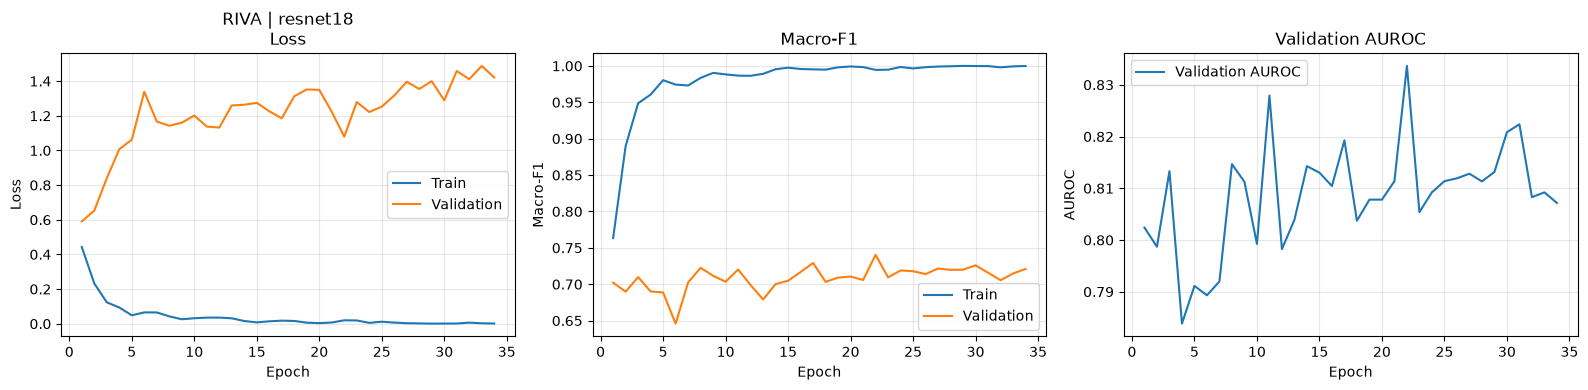

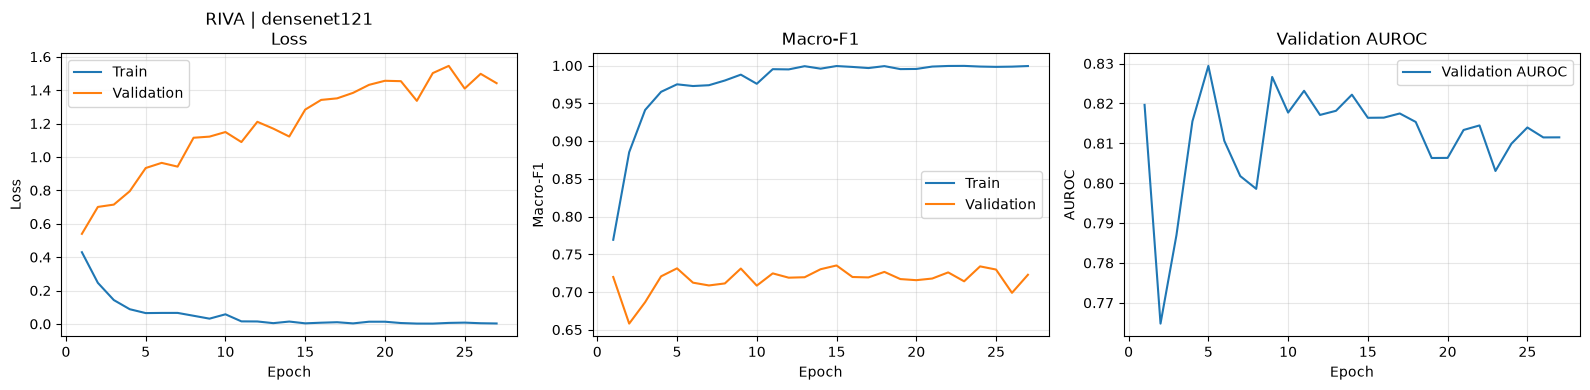

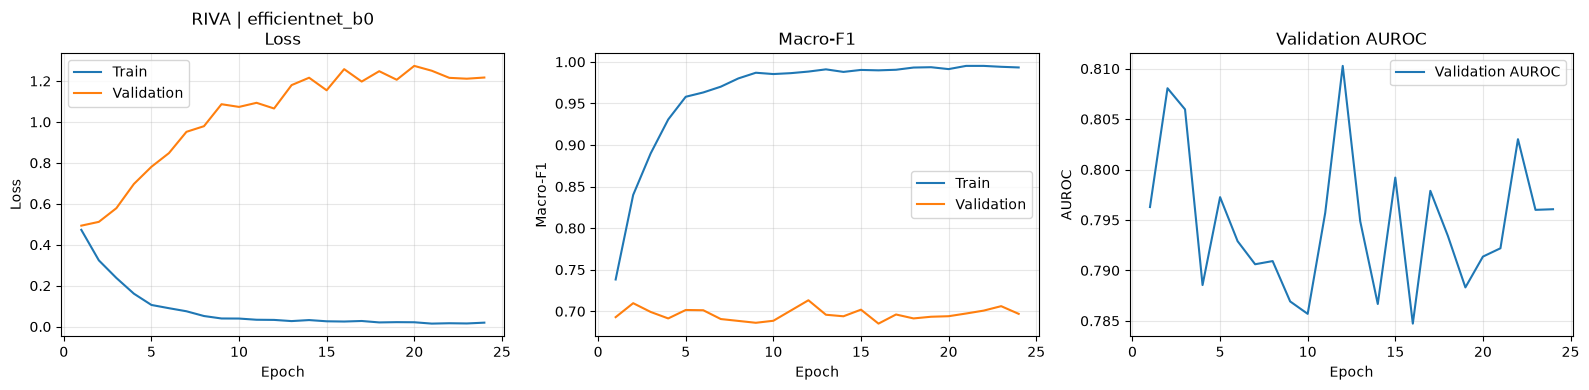

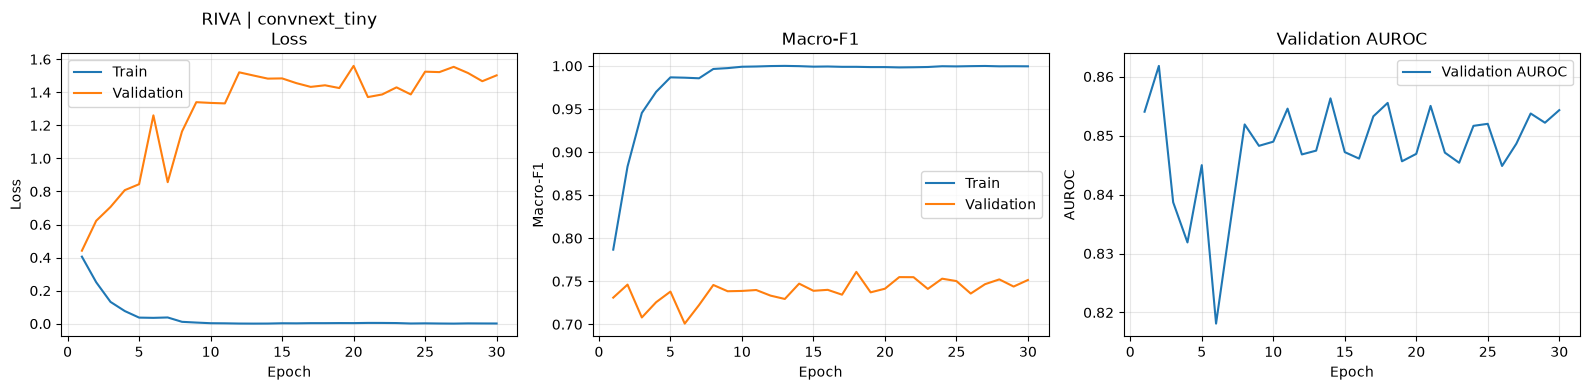

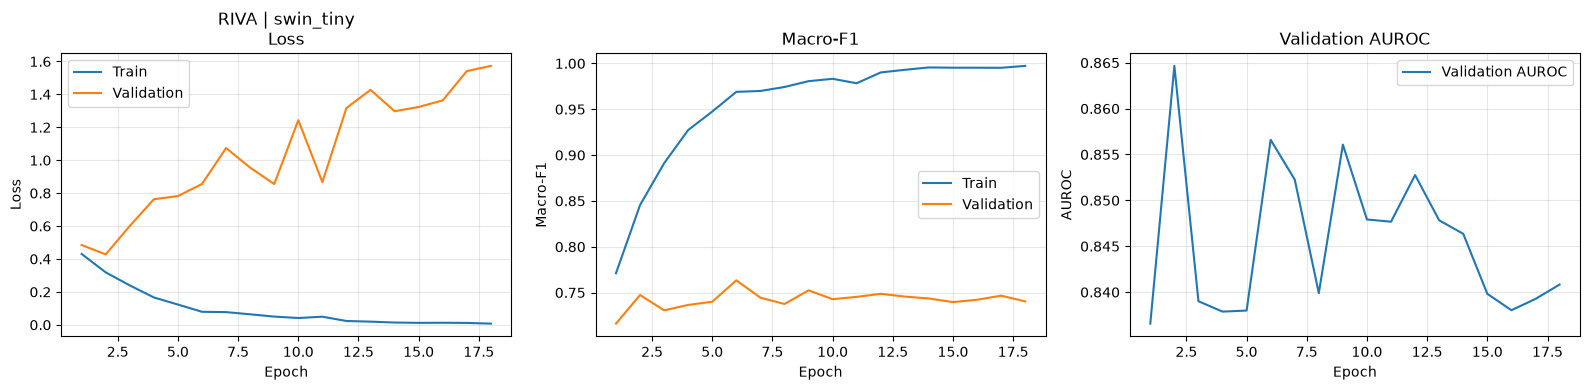

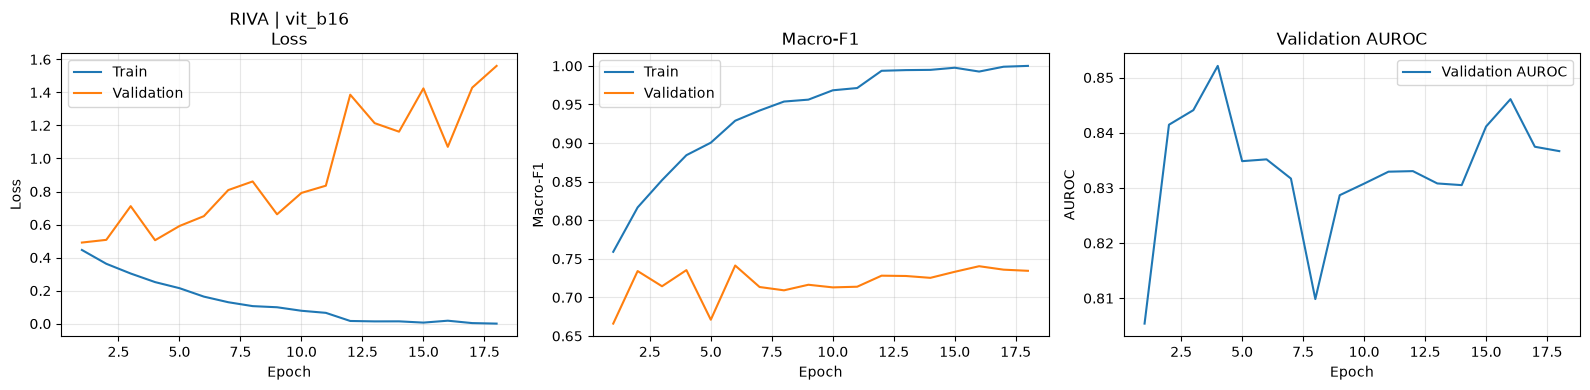

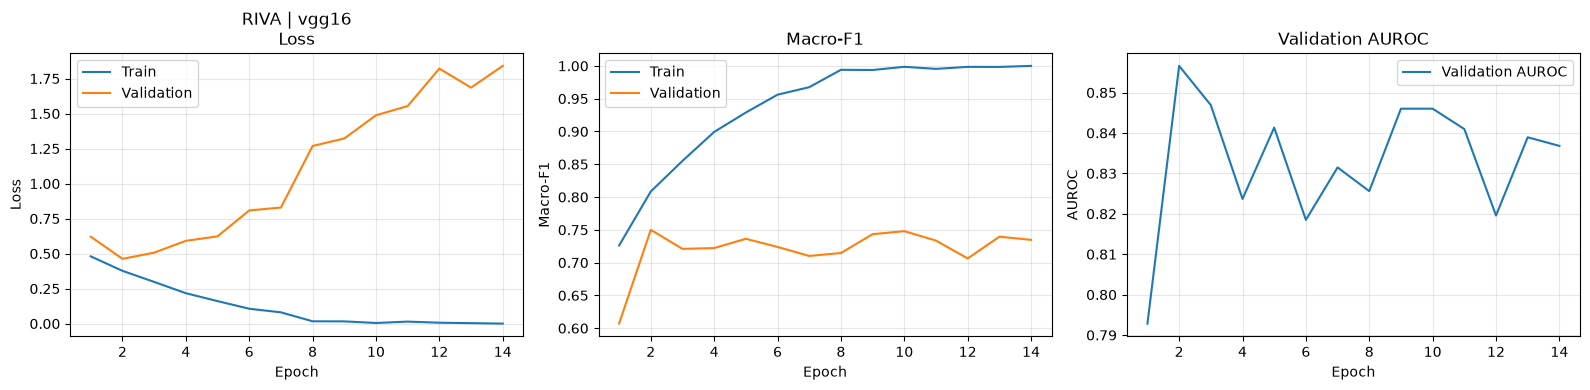

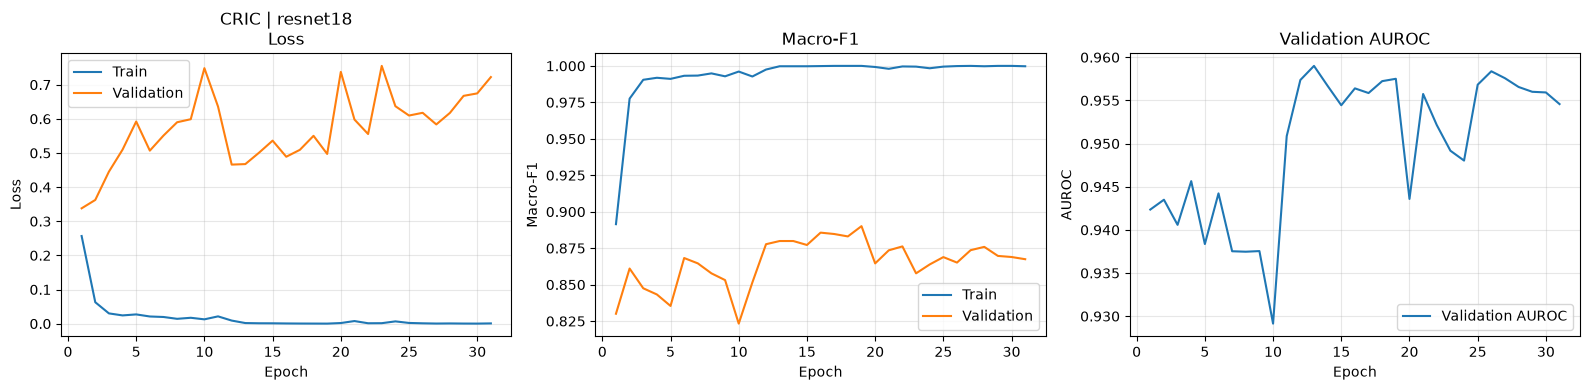

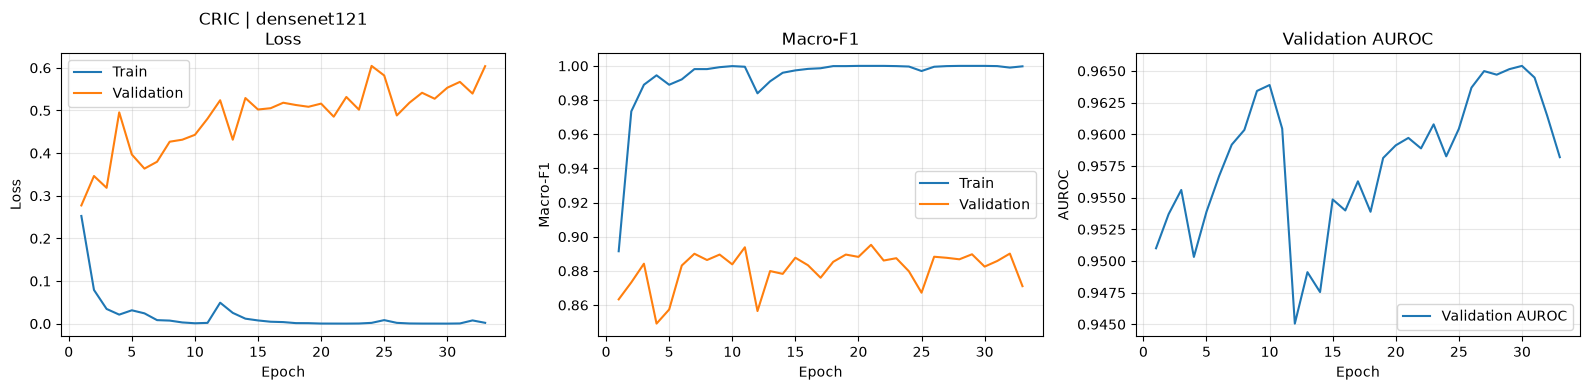

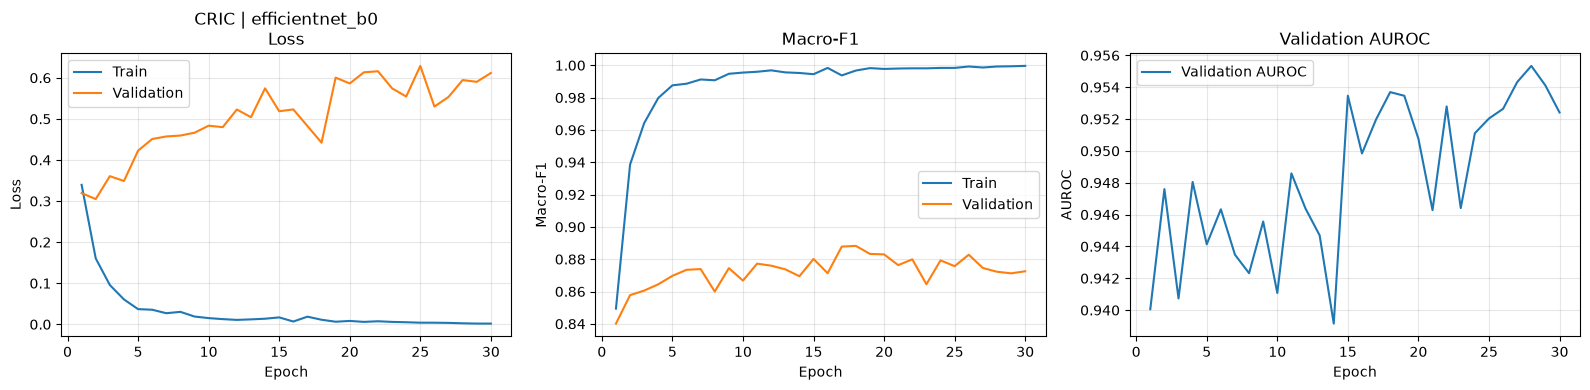

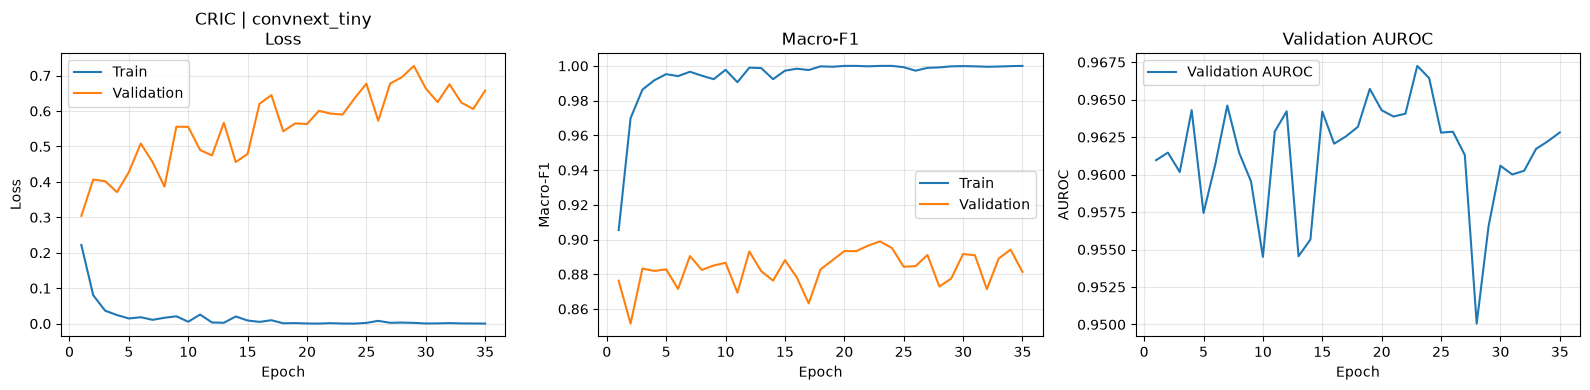

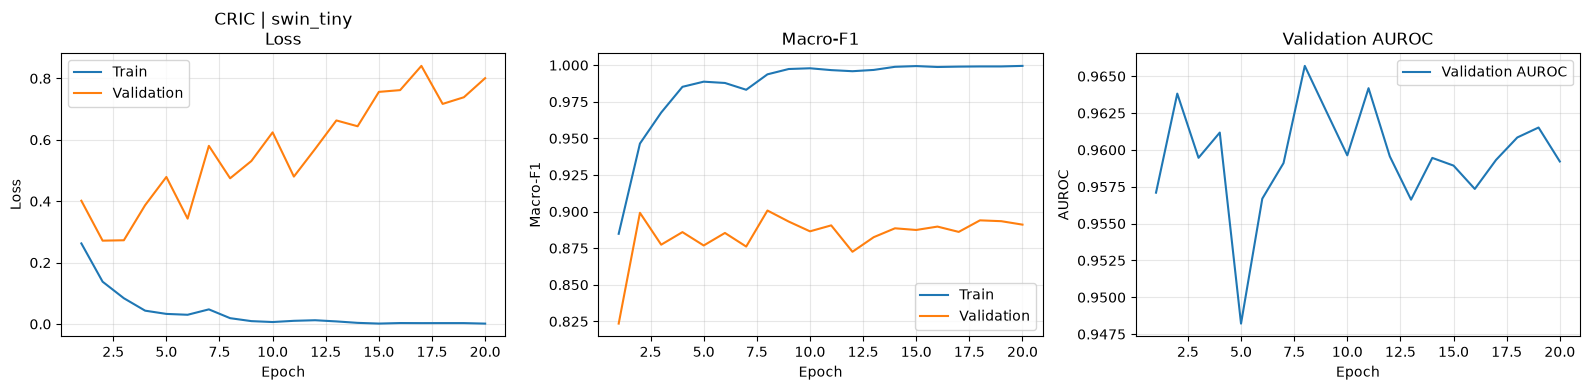

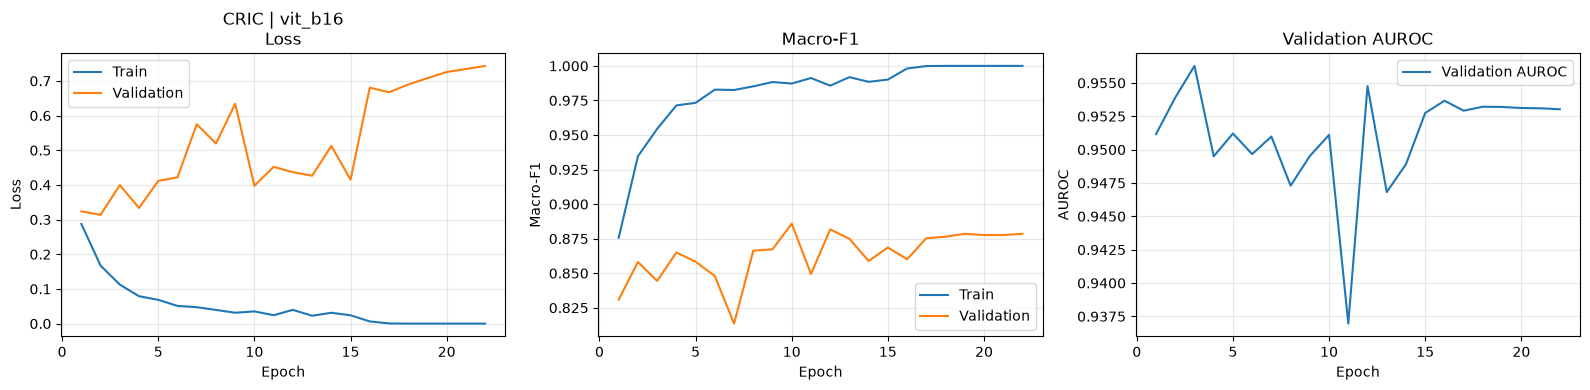

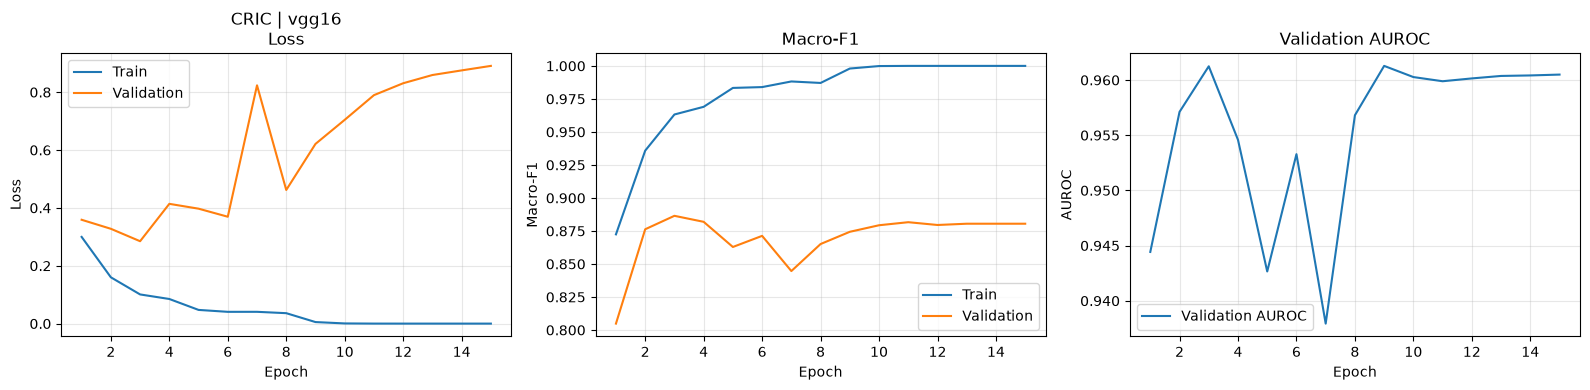

In [35]:
# Plot training loss, validation loss, and validation Macro-F1
for dataset_name in ["riva", "cric"]:
    for model_name in MODEL_NAMES:
        paths = get_run_paths(model_name, dataset_name)
        history_path = paths["history"]

        if not history_path.exists():
            print("MISSING HISTORY:", dataset_name, model_name)
            continue

        history = pd.read_csv(history_path)

        required = ["epoch", "train_loss", "val_loss", "val_macro_f1"]
        missing = [col for col in required if col not in history.columns]

        if missing:
            print("Missing columns:", dataset_name, model_name, missing)
            continue

        fig, axes = plt.subplots(1, 3, figsize=(16, 4))

        axes[0].plot(history["epoch"], history["train_loss"], label="Train")
        axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
        axes[0].set_title(f"{dataset_name.upper()} | {model_name}\nLoss")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Loss")
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)

        axes[1].plot(history["epoch"], history["train_macro_f1"], label="Train")
        axes[1].plot(history["epoch"], history["val_macro_f1"], label="Validation")
        axes[1].set_title("Macro-F1")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Macro-F1")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)

        axes[2].plot(history["epoch"], history["val_auroc"], label="Validation AUROC")
        axes[2].set_title("Validation AUROC")
        axes[2].set_xlabel("Epoch")
        axes[2].set_ylabel("AUROC")
        axes[2].legend()
        axes[2].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

In [34]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Results root:", RESULTS_ROOT)
print("Results root exists:", RESULTS_ROOT.exists())
print("Models:", MODEL_NAMES)

for dataset_name in ["riva", "cric"]:
    print(f"\n{dataset_name.upper()} split counts:")
    split_df = riva_splits if dataset_name == "riva" else cric_splits
    print(split_df["split"].value_counts(dropna=False))

print("\nExample run artifacts:")
for model_name in MODEL_NAMES:
    paths = get_run_paths(model_name, "riva")
    print(
        model_name,
        "| history:", paths["history"].exists(),
        "| best:", paths["best"].exists(),
        "| metrics:", paths["metrics"].exists()
    )

Results root: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase09_v2
Results root exists: True
Models: ['resnet18', 'densenet121', 'efficientnet_b0', 'convnext_tiny', 'swin_tiny', 'vit_b16', 'vgg16']

RIVA split counts:
split
train         11171
test           3196
validation     1582
Name: count, dtype: int64

CRIC split counts:
split
train         8074
test          2307
validation    1153
Name: count, dtype: int64

Example run artifacts:
resnet18 | history: True | best: True | metrics: True
densenet121 | history: True | best: True | metrics: True
efficientnet_b0 | history: True | best: True | metrics: True
convnext_tiny | history: True | best: True | metrics: True
swin_tiny | history: True | best: True | metrics: True
vit_b16 | history: True | best: True | metrics: True
vgg16 | history: True | best: True | metrics: True


PHASE 09 V2 — COMBINED DIAGNOSTICS AUDIT


[1] SPLIT GROUP-OVERLAP AUDIT

--- RIVA ---
Columns: ['dataset', 'image_filename', 'x_norm', 'y_norm', 'class_bethesda', 'class_annotated', 'cluster_idx', 'binary_label', 'x_pixel', 'y_pixel', 'crop_path', 'crop_valid', 'slide_id', 'split']
Chosen group column: slide_id
Unique groups: 111
Groups present in multiple splits: 0
No overlap detected for this group field.
NOTE: this is valid only if the chosen field is the correct group ID.

--- CRIC ---
Columns: ['dataset', 'image_filename', 'cell_id', 'x_pixel', 'y_pixel', 'class_bethesda', 'binary_label', 'crop_path', 'crop_valid', 'split']
CHECK REQUIRED: no obvious group column found.
Verify the actual slide/image identifier from the columns above.


[2] MANIFEST VS SPLIT LABEL AUDIT

--- RIVA ---
Manifest missing: C:\Users\nanda\Documents\cervical-semi-sl\notebooks\data\processed\riva_learning_units.csv

--- CRIC ---
Manifest missing: C:\Users\nanda\Documents\cervical-semi-sl\notebooks\data\pr

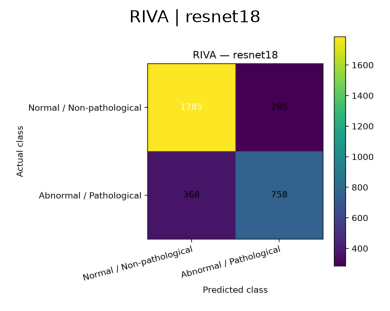

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.829076            0.862319  0.845371     2070
  Abnormal / Pathological   0.726750            0.673179  0.698940     1126

--- RIVA | densenet121 ---


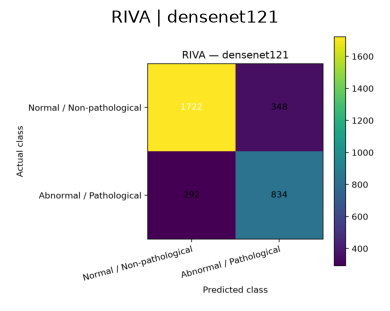

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.855015            0.831884  0.843291     2070
  Abnormal / Pathological   0.705584            0.740675  0.722704     1126

--- RIVA | efficientnet_b0 ---


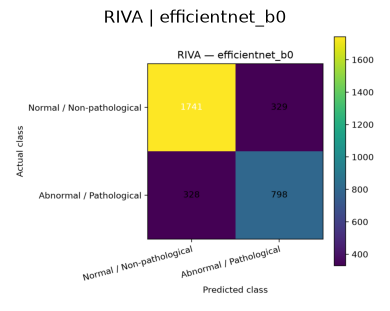

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.841469            0.841063  0.841266     2070
  Abnormal / Pathological   0.708075            0.708703  0.708389     1126

--- RIVA | convnext_tiny ---


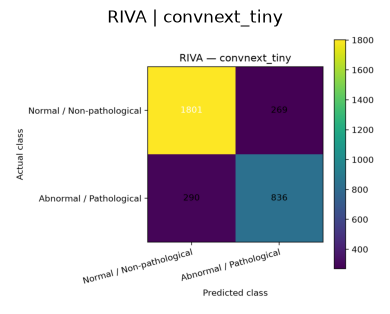

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.861310            0.870048  0.865657     2070
  Abnormal / Pathological   0.756561            0.742451  0.749440     1126

--- RIVA | swin_tiny ---


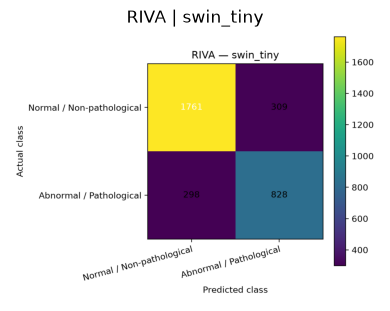

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.855270            0.850725  0.852991     2070
  Abnormal / Pathological   0.728232            0.735346  0.731772     1126

--- RIVA | vit_b16 ---


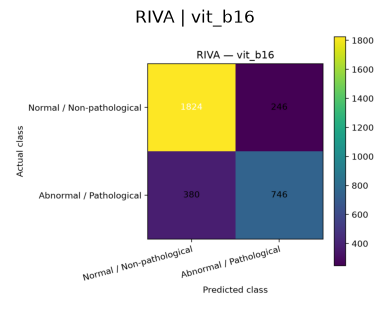

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.827586            0.881159  0.853533     2070
  Abnormal / Pathological   0.752016            0.662522  0.704438     1126

--- RIVA | vgg16 ---


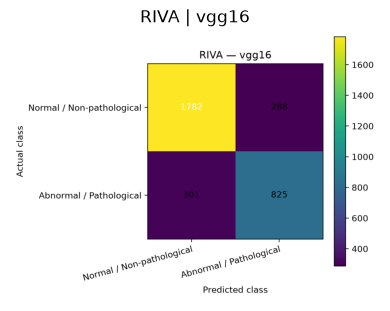

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.855497            0.860870  0.858175     2070
  Abnormal / Pathological   0.741240            0.732682  0.736936     1126

--- CRIC | resnet18 ---


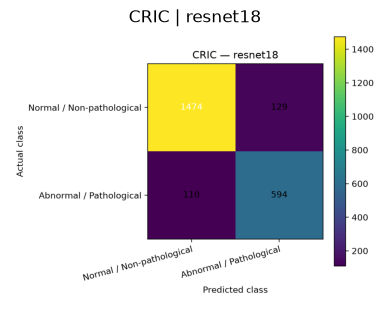

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.930556            0.919526  0.925008     1603
  Abnormal / Pathological   0.821577            0.843750  0.832516      704

--- CRIC | densenet121 ---


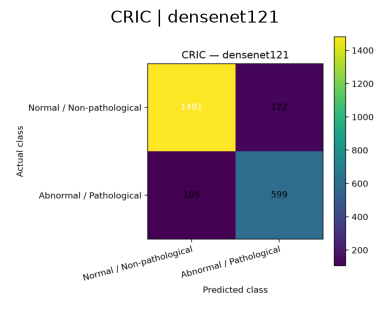

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.933796            0.923893  0.928818     1603
  Abnormal / Pathological   0.830791            0.850852  0.840702      704

--- CRIC | efficientnet_b0 ---


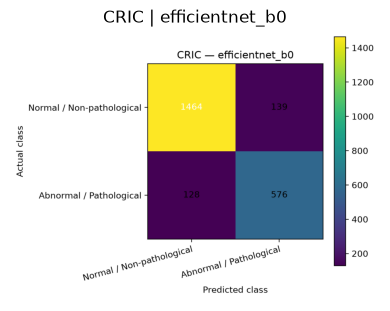

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.919598            0.913288  0.916432     1603
  Abnormal / Pathological   0.805594            0.818182  0.811839      704

--- CRIC | convnext_tiny ---


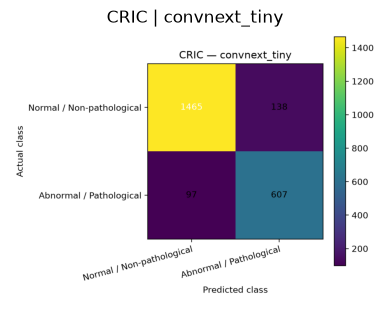

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.937900            0.913911  0.925750     1603
  Abnormal / Pathological   0.814765            0.862216  0.837819      704

--- CRIC | swin_tiny ---


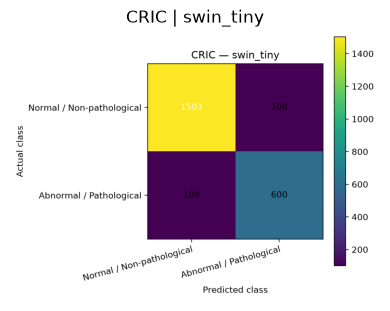

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.935283            0.937617  0.936449     1603
  Abnormal / Pathological   0.857143            0.852273  0.854701      704

--- CRIC | vit_b16 ---


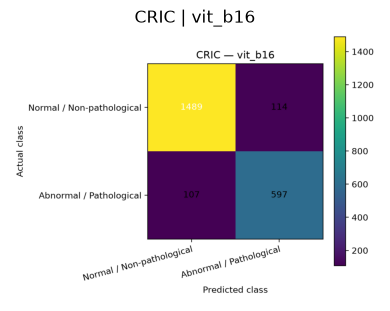

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.932957            0.928883  0.930916     1603
  Abnormal / Pathological   0.839662            0.848011  0.843816      704

--- CRIC | vgg16 ---


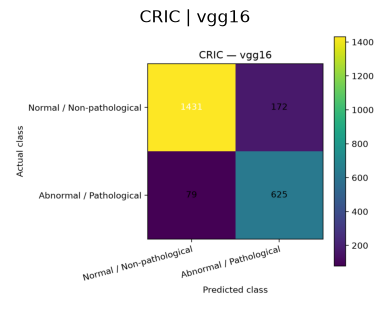

                    class  precision  recall_sensitivity  f1_score  support
Normal / Non-pathological   0.947682            0.892701  0.919370     1603
  Abnormal / Pathological   0.784191            0.887784  0.832778      704

COMBINED AUDIT COMPLETE — NO MODELS RETRAINED


In [36]:
# PHASE 09 V2 — COMBINED DIAGNOSTICS AUDIT
# Read-only audit: does not train models or modify existing splits/checkpoints.

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 85)
print("PHASE 09 V2 — COMBINED DIAGNOSTICS AUDIT")
print("=" * 85)

# ---------------------------------------------------------
# 1. SPLIT GROUP-OVERLAP AUDIT
# ---------------------------------------------------------
print("\n\n[1] SPLIT GROUP-OVERLAP AUDIT")

group_candidates = [
    "group_id", "group", "slide_id", "parent_image",
    "parent_image_id", "image_id", "source_image", "filename"
]

for dataset_name, split_df in [
    ("RIVA", riva_splits),
    ("CRIC", cric_splits)
]:
    print(f"\n--- {dataset_name} ---")
    print("Columns:", split_df.columns.tolist())

    split_col = next(
        (c for c in split_df.columns if c.lower() == "split"), None
    )
    group_col = next(
        (c for c in group_candidates if c in split_df.columns), None
    )

    if split_col is None:
        print("WARNING: no split column found.")
        continue

    if group_col is None:
        print("CHECK REQUIRED: no obvious group column found.")
        print("Verify the actual slide/image identifier from the columns above.")
        continue

    temp = split_df[[split_col, group_col]].dropna().copy()
    temp[split_col] = temp[split_col].astype(str).str.lower().str.strip()

    group_counts = temp.groupby(group_col)[split_col].nunique()
    overlap = group_counts[group_counts > 1]

    print("Chosen group column:", group_col)
    print("Unique groups:", temp[group_col].nunique())
    print("Groups present in multiple splits:", len(overlap))

    if len(overlap):
        print("Potential overlap examples:")
        print(overlap.head(10).to_string())
    else:
        print("No overlap detected for this group field.")
        print("NOTE: this is valid only if the chosen field is the correct group ID.")

# ---------------------------------------------------------
# 2. MANIFEST VS SPLIT LABEL AUDIT
# ---------------------------------------------------------
print("\n\n[2] MANIFEST VS SPLIT LABEL AUDIT")

manifest_paths = {
    "riva": Path("data/processed/riva_learning_units.csv"),
    "cric": Path("data/processed/cric_learning_units.csv")
}
split_tables = {"riva": riva_splits, "cric": cric_splits}

for dataset_name, manifest_path in manifest_paths.items():
    print(f"\n--- {dataset_name.upper()} ---")
    if not manifest_path.exists():
        print("Manifest missing:", manifest_path.resolve())
        continue

    manifest = pd.read_csv(manifest_path)
    split_df = split_tables[dataset_name]

    label_candidates = ["binary_label", "label", "target"]
    manifest_label = next(
        (c for c in label_candidates if c in manifest.columns), None
    )
    split_label = next(
        (c for c in label_candidates if c in split_df.columns), None
    )

    print("Manifest rows:", len(manifest))
    print("Split rows:", len(split_df))

    if manifest_label:
        print("\nManifest binary-label counts:")
        print(manifest[manifest_label].value_counts(dropna=False).sort_index())
        print("Missing manifest labels:", manifest[manifest_label].isna().sum())
        print(
            "Unexpected manifest labels:",
            manifest.loc[
                manifest[manifest_label].notna()
                & ~manifest[manifest_label].isin([0, 1]),
                manifest_label
            ].unique()
        )
    else:
        print("No binary label column identified in manifest.")

    if split_label:
        print("\nSplit binary-label counts:")
        print(split_df[split_label].value_counts(dropna=False).sort_index())
        print("Missing split labels:", split_df[split_label].isna().sum())
    else:
        print("No binary label column identified in split table.")

    # If both tables have a shared identifier, verify that binary labels agree.
    id_candidates = [
        "unit_id", "crop_path", "crop_filename", "filename",
        "image_path", "path", "sample_id"
    ]
    shared_id = next(
        (
            c for c in id_candidates
            if c in manifest.columns and c in split_df.columns
        ),
        None
    )

    if shared_id and manifest_label and split_label:
        left = manifest[[shared_id, manifest_label]].dropna().copy()
        right = split_df[[shared_id, split_label]].dropna().copy()

        left = left.rename(columns={manifest_label: "_manifest_label"})
        right = right.rename(columns={split_label: "_split_label"})

        # Avoid misleading comparisons if the identifier is not unique.
        if left[shared_id].is_unique and right[shared_id].is_unique:
            merged = left.merge(right, on=shared_id, how="inner")
            mismatches = merged[
                merged["_manifest_label"] != merged["_split_label"]
            ]
            print("\nShared ID column:", shared_id)
            print("Matched rows:", len(merged))
            print("Label mismatches:", len(mismatches))
            if len(mismatches):
                print(mismatches.head(10).to_string(index=False))
        else:
            print(
                "\nSkipped row-level label comparison: shared identifier "
                "is not unique in both tables."
            )
    else:
        print("\nNo suitable shared identifier found for row-level comparison.")

# ---------------------------------------------------------
# 3. TRAINING / VALIDATION GAP AT BEST VALIDATION MACRO-F1
# ---------------------------------------------------------
print("\n\n[3] TRAINING / VALIDATION GAP")

diagnostic_rows = []

for dataset_name in ["riva", "cric"]:
    for model_name in MODEL_NAMES:
        paths = get_run_paths(model_name, dataset_name)
        history_path = paths["history"]

        if not history_path.exists():
            print("Missing history:", dataset_name, model_name)
            continue

        history = pd.read_csv(history_path)

        needed = [
            "epoch", "train_macro_f1", "val_macro_f1",
            "train_loss", "val_loss", "val_auroc"
        ]
        missing = [c for c in needed if c not in history.columns]

        if missing:
            print("Missing columns:", dataset_name, model_name, missing)
            continue

        valid_history = history.dropna(subset=["val_macro_f1"])
        if valid_history.empty:
            print("No valid validation Macro-F1:", dataset_name, model_name)
            continue

        best = valid_history.loc[valid_history["val_macro_f1"].idxmax()]

        diagnostic_rows.append({
            "dataset": dataset_name,
            "model": model_name,
            "epochs": len(history),
            "best_val_epoch": int(best["epoch"]),
            "train_macro_f1_at_best": float(best["train_macro_f1"]),
            "best_val_macro_f1": float(best["val_macro_f1"]),
            "train_val_f1_gap": float(
                best["train_macro_f1"] - best["val_macro_f1"]
            ),
            "train_loss_at_best": float(best["train_loss"]),
            "val_loss_at_best": float(best["val_loss"]),
            "val_auroc_at_best_f1_epoch": float(best["val_auroc"])
        })

diagnostics_df = pd.DataFrame(diagnostic_rows)

if not diagnostics_df.empty:
    print(
        diagnostics_df.sort_values(
            ["dataset", "best_val_macro_f1"],
            ascending=[True, False]
        ).round(4).to_string(index=False)
    )

    diagnostics_path = RESULTS_ROOT / "training_diagnostics_summary_v2.csv"
    diagnostics_df.to_csv(diagnostics_path, index=False)
    print("\nSaved training summary:", diagnostics_path)

# ---------------------------------------------------------
# 4. TEST CONFUSION MATRICES AND PER-CLASS METRICS
# ---------------------------------------------------------
print("\n\n[4] SAVED TEST CONFUSION MATRICES AND PER-CLASS METRICS")

for dataset_name in ["riva", "cric"]:
    for model_name in MODEL_NAMES:
        paths = get_run_paths(model_name, dataset_name)
        run_dir = paths["run_dir"]
        cm_path = run_dir / "confusion_matrix.png"
        per_class_path = run_dir / "per_class_metrics.csv"

        print(f"\n--- {dataset_name.upper()} | {model_name} ---")

        if cm_path.exists():
            image_array = plt.imread(cm_path)
            plt.figure(figsize=(4, 3.5))
            plt.imshow(image_array)
            plt.axis("off")
            plt.title(f"{dataset_name.upper()} | {model_name}")
            plt.tight_layout()
            plt.show()
        else:
            print("Missing confusion matrix:", cm_path)

        if per_class_path.exists():
            print(pd.read_csv(per_class_path).to_string(index=False))
        else:
            print("Missing per-class metrics:", per_class_path)

print("\n" + "=" * 85)
print("COMBINED AUDIT COMPLETE — NO MODELS RETRAINED")
print("=" * 85)

In [38]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"C:\Users\nanda\Documents\cervical-semi-sl")

datasets = {
    "RIVA": {
        "manifest_path": PROJECT_ROOT / "data/processed/riva_learning_units.csv",
        "splits": riva_splits.copy(),
        "group_col": "slide_id",
    },
    "CRIC": {
        "manifest_path": PROJECT_ROOT / "data/processed/cric_learning_units.csv",
        "splits": cric_splits.copy(),
        "group_col": "image_filename",
    },
}

for name, info in datasets.items():
    print("\n" + "=" * 75)
    print(name)

    manifest_path = info["manifest_path"]
    split_df = info["splits"]
    group_col = info["group_col"]

    # 1. Check split group overlap
    if "split" not in split_df.columns:
        print("ERROR: split column missing.")
        print("Columns:", split_df.columns.tolist())
        continue

    split_df["split"] = (
        split_df["split"].astype(str).str.lower().str.strip()
    )

    if group_col in split_df.columns:
        group_counts = (
            split_df.dropna(subset=[group_col])
            .groupby(group_col)["split"]
            .nunique()
        )
        overlap = group_counts[group_counts > 1]

        print("Group column:", group_col)
        print("Unique groups:", split_df[group_col].nunique())
        print("Groups overlapping splits:", len(overlap))
        if len(overlap):
            print(overlap.head(10).to_string())
    else:
        print("GROUP CHECK NEEDS ATTENTION: missing", group_col)

    # 2. Load manifest
    if not manifest_path.exists():
        print("MANIFEST NOT FOUND:", manifest_path)
        continue

    manifest = pd.read_csv(manifest_path)
    print("Manifest rows:", len(manifest))
    print("Split rows:", len(split_df))
    print("Manifest columns:", manifest.columns.tolist())
    print("Split columns:", split_df.columns.tolist())

    # Use crop_path as the row identifier when available.
    id_col = "crop_path" if (
        "crop_path" in manifest.columns and
        "crop_path" in split_df.columns
    ) else None

    if id_col is None:
        print("No shared crop identifier found; row-level audit skipped.")
        continue

    # Rename label fields BEFORE merging to avoid duplicate-name problems.
    if "binary_label" not in manifest.columns:
        print("Manifest has no binary_label column.")
        continue
    if "binary_label" not in split_df.columns:
        print("Split table has no binary_label column.")
        continue

    left = manifest[[id_col, "binary_label"]].copy()
    right = split_df[[id_col, "binary_label"]].copy()

    left = left.rename(columns={"binary_label": "manifest_label"})
    right = right.rename(columns={"binary_label": "split_label"})

    # Normalize path strings for matching.
    left[id_col] = left[id_col].astype(str).str.replace("\\", "/", regex=False)
    right[id_col] = right[id_col].astype(str).str.replace("\\", "/", regex=False)

    # Duplicate IDs can make a merge ambiguous, so report them.
    print("Duplicate manifest IDs:", left[id_col].duplicated().sum())
    print("Duplicate split IDs:", right[id_col].duplicated().sum())

    left = left.drop_duplicates(subset=[id_col])
    right = right.drop_duplicates(subset=[id_col])

    joined = left.merge(right, on=id_col, how="outer", indicator=True)

    both = joined[joined["_merge"] == "both"].copy()
    only_manifest = (joined["_merge"] == "left_only").sum()
    only_split = (joined["_merge"] == "right_only").sum()

    # Convert labels to numeric for comparison.
    both["manifest_label"] = pd.to_numeric(
        both["manifest_label"], errors="coerce"
    )
    both["split_label"] = pd.to_numeric(
        both["split_label"], errors="coerce"
    )

    mismatches = both[
        both["manifest_label"] != both["split_label"]
    ]

    print("\nIdentifier:", id_col)
    print("Matched IDs:", len(both))
    print("Only in manifest:", only_manifest)
    print("Only in split table:", only_split)
    print("Label mismatches:", len(mismatches))

    if len(mismatches):
        print("Example mismatches:")
        print(mismatches[[id_col, "manifest_label", "split_label"]]
              .head(10).to_string(index=False))

    print("\nManifest label counts:")
    print(manifest["binary_label"].value_counts(dropna=False).sort_index())

    print("\nSplit label counts:")
    print(split_df["binary_label"].value_counts(dropna=False).sort_index())

print("\nAUDIT COMPLETE — no models retrained and no files modified.")



RIVA
Group column: slide_id
Unique groups: 111
Groups overlapping splits: 0
Manifest rows: 15949
Split rows: 15949
Manifest columns: ['dataset', 'image_filename', 'x_norm', 'y_norm', 'class_bethesda', 'class_annotated', 'cluster_idx', 'binary_label', 'x_pixel', 'y_pixel', 'crop_path', 'crop_valid']
Split columns: ['dataset', 'image_filename', 'x_norm', 'y_norm', 'class_bethesda', 'class_annotated', 'cluster_idx', 'binary_label', 'x_pixel', 'y_pixel', 'crop_path', 'crop_valid', 'slide_id', 'split']
Duplicate manifest IDs: 0
Duplicate split IDs: 0

Identifier: crop_path
Matched IDs: 15949
Only in manifest: 0
Only in split table: 0
Label mismatches: 0

Manifest label counts:
binary_label
0    10517
1     5432
Name: count, dtype: int64

Split label counts:
binary_label
0    10517
1     5432
Name: count, dtype: int64

CRIC
Group column: image_filename
Unique groups: 400
Groups overlapping splits: 0
Manifest rows: 11534
Split rows: 11534
Manifest columns: ['dataset', 'image_filename', 'cell